# CLIP Remote Sensing, LoRA and Retrieval

Portfolio edition: Behrad Mazaheri. Template/source credit: Source header: Dr. Soleymani, Spring 2026.

**Static review only — not rerun.** Outputs below are retained from `P2_completed(1).ipynb`, including failures or missing executions. They do not validate later revisions. Read README and REVIEW before running cells or citing metrics. Source cell references use zero-based indices before this added banner.


# CLIP Vision Analysis

### DL Course, Dr. Soleymani

Spring **2026**

---
*Full Name:* ...behrad mazaheri

*SID:* ...[student ID removed]

---
We have specified the parts to be completed with `TODO` tags inside the code blocks.

**NOTES**:
* This notebook is tested with *Google Colab* free runtime and you can used that for testing your code.
* Ensure all cells are executable

# CLIP: Mathematical Idea and Notebook Workflow

CLIP uses two encoders: one for images and one for text.  
Each image and each text prompt is mapped to a shared embedding space.

After L2-normalization, image-text matching is computed with cosine similarity:

$
s(i,t)=\tau \cdot z_i^\top z_t
$

where $z_i$ is the image embedding, $z_t$ is the text embedding, and $\tau$ is CLIP's learned logit scale.

In this notebook, we first use CLIP without training for zero-shot classification.  
Then we analyze embeddings, study prompt sensitivity, fine-tune CLIP with LoRA, use the embeddings for retrieval, and finally test the fine-tuned text encoder inside Stable Diffusion.

# Part 0 — Environment, Dataset, and Model Setup

This part prepares the notebook for all later experiments.

It installs the required packages, checks the GPU, loads CLIP, loads the RESISC45 dataset, prepares class labels, and builds PyTorch datasets and dataloaders.

## 0.1 Install required packages

This cell installs the main libraries used for CLIP, datasets, LoRA fine-tuning, retrieval, visualization, and image generation.

In [11]:
%%capture
%pip install -q -U \
    datasets \
    transformers \
    accelerate \
    peft \
    diffusers \
    safetensors \
    scikit-learn \
    faiss-cpu \
    pillow \
    matplotlib \
    seaborn \
    tqdm \
    pandas \
    numpy \
    psutil

## 0.2 Check GPU runtime

This cell checks whether CUDA is available and reports the GPU type.

The notebook is designed to run on Google Colab with a GPU T4 runtime.

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9

    print("GPU name:", gpu_name)
    print(f"GPU memory: {gpu_memory:.2f} GB")

else:
    print("Warning: No GPU was detected.")

PyTorch version: 2.7.1+cu126
CUDA available: True
GPU name: NVIDIA GeForce GTX 1650
GPU memory: 4.29 GB


## 0.3 Import shared libraries

This cell imports the shared libraries used across the notebook for data loading, modeling, evaluation, visualization, retrieval, fine-tuning, and generation.

In [2]:
import os
import gc
import json
import time
import math
import random
import sys
import subprocess
import importlib.util
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset

from transformers import (
    CLIPModel,
    CLIPProcessor,
    CLIPTextModel,
    get_cosine_schedule_with_warmup,
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

import faiss

from peft import LoraConfig, get_peft_model, PeftModel

from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.4 Define project configuration

This cell defines the main paths, model IDs, device, batch size, and random seed.

The main CLIP model is `openai/clip-vit-large-patch14`.  

In [3]:
PROJECT_DIR = Path("/content/resisc45_clip_project")
CACHE_DIR = PROJECT_DIR / "hf_cache"
OUTPUT_DIR = PROJECT_DIR / "outputs"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ID = "timm/resisc45"

# Main CLIP model used across Parts 0-5
CLIP_MODEL_ID = "openai/clip-vit-large-patch14"

# Stable Diffusion v1.x uses a compatible CLIP text encoder family
SD_TEXT_ENCODER_REFERENCE_ID = "openai/clip-vit-large-patch14"

# Stable Diffusion model for Part 6
SD_MODEL_ID = "runwayml/stable-diffusion-v1-5"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RANDOM_SEED = 42

# Conservative batch size for full-test ViT-L/14 evaluation on Colab T4
BATCH_SIZE = 16 if torch.cuda.is_available() else 8
NUM_WORKERS = 0
######2
CONFIG = {
    "project_dir": str(PROJECT_DIR),
    "cache_dir": str(CACHE_DIR),
    "output_dir": str(OUTPUT_DIR),
    "dataset_id": DATASET_ID,
    "clip_model_id": CLIP_MODEL_ID,
    "sd_text_encoder_reference_id": SD_TEXT_ENCODER_REFERENCE_ID,
    "sd_model_id": SD_MODEL_ID,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "random_seed": RANDOM_SEED,
}

print(json.dumps(CONFIG, indent=2))

{
  "project_dir": "\\content\\resisc45_clip_project",
  "cache_dir": "\\content\\resisc45_clip_project\\hf_cache",
  "output_dir": "\\content\\resisc45_clip_project\\outputs",
  "dataset_id": "timm/resisc45",
  "clip_model_id": "openai/clip-vit-large-patch14",
  "sd_text_encoder_reference_id": "openai/clip-vit-large-patch14",
  "sd_model_id": "runwayml/stable-diffusion-v1-5",
  "device": "cuda",
  "batch_size": 16,
  "num_workers": 0,
  "random_seed": 42
}


## 0.5 Set random seed

This cell fixes the random seed for Python, NumPy, and PyTorch to make sampling and training more reproducible.

In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Keep runs more reproducible.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


set_seed(RANDOM_SEED)

## 0.6 Load CLIP model and processor

This cell loads the CLIP model and its processor from Hugging Face.

The processor prepares both images and text inputs, while the model produces image and text embeddings in the same semantic space.

In [5]:
print("Loading CLIP model:", CLIP_MODEL_ID)

processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
model = CLIPModel.from_pretrained(CLIP_MODEL_ID)

model = model.to(DEVICE)
model.eval()

print("Model loaded.")
print("Device:", DEVICE)
print("Projection dimension:", model.config.projection_dim)
print("Vision model type:", model.config.vision_config.model_type)
print("Text model type:", model.config.text_config.model_type)

Loading CLIP model: openai/clip-vit-large-patch14


c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Model loaded.
Device: cuda
Projection dimension: 768
Vision model type: clip_vision_model
Text model type: clip_text_model


## 0.7 Load RESISC45 dataset

This cell loads the RESISC45 remote-sensing dataset from Hugging Face.

In [6]:
raw_ds = load_dataset(
    DATASET_ID,
    cache_dir=str(CACHE_DIR),
)

print(raw_ds)
print("Available splits:", list(raw_ds.keys()))

required_splits = {"train", "test"}
missing_splits = required_splits - set(raw_ds.keys())

if missing_splits:
    raise ValueError(f"Missing required splits: {missing_splits}")

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 18900
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 6300
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 6300
    })
})
Available splits: ['train', 'validation', 'test']


## 0.8 Inspect dataset structure and class labels

This cell extracts class names, creates label mappings, and displays a summary of the dataset splits.

In [7]:
train_ds = raw_ds["train"]
validation_ds = raw_ds["validation"] if "validation" in raw_ds else None
test_full_ds = raw_ds["test"]

test_eval_ds = test_full_ds

label_feature = train_ds.features["label"]

class_names = list(label_feature.names)
num_classes = len(class_names)

class_names_clean = [
    name.replace("_", " ")
    for name in class_names
]

label2id = {
    name: idx
    for idx, name in enumerate(class_names)
}

id2label = {
    idx: name
    for idx, name in enumerate(class_names)
}

split_summary = pd.DataFrame([
    {
        "split": split_name,
        "num_images": len(split_data),
    }
    for split_name, split_data in raw_ds.items()
])

display(split_summary)

print("Number of classes:", num_classes)
print("First 10 class names:", class_names[:10])
print("First 10 cleaned class names:", class_names_clean[:10])

sample = train_ds[0]

print("\nSample")
print("------")
print("Image type:", type(sample["image"]))
print("Label id:", sample["label"])
print("Label name:", id2label[sample["label"]])

if "image_id" in sample:
    print("Image id:", sample["image_id"])

,split,num_images
0,train,18900
1,validation,6300
2,test,6300


Number of classes: 45
First 10 class names: ['airplane', 'airport', 'baseball_diamond', 'basketball_court', 'beach', 'bridge', 'chaparral', 'church', 'circular_farmland', 'cloud']
First 10 cleaned class names: ['airplane', 'airport', 'baseball diamond', 'basketball court', 'beach', 'bridge', 'chaparral', 'church', 'circular farmland', 'cloud']

Sample
------
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Label id: 32
Label name: river
Image id: river_066


## 0.9 Build PyTorch datasets and dataloaders

This cell wraps the Hugging Face dataset in a PyTorch dataset.

In [8]:
class RESISC45Dataset(Dataset):
    """
    A PyTorch Dataset wrapper for the RESISC45 Hugging Face dataset.
    """

    def __init__(self, hf_dataset, id2label):
        self.hf_dataset = hf_dataset
        self.id2label = dict(id2label)

    def __len__(self):
        return len(self.hf_dataset)

    def __getitem__(self, index):
        sample = self.hf_dataset[int(index)]
        image = sample["image"]

        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))

        image = image.convert("RGB")
        label = int(sample["label"])
        image_id = str(sample.get("image_id", index))

        return {
            "image": image,
            "label": label,
            "class_name": self.id2label[label],
            "image_id": image_id,
        }


def collate_pil_batch(batch):
    if len(batch) == 0:
        raise ValueError("Cannot collate an empty batch.")

    return {
        "images": [sample["image"] for sample in batch],
        "labels": torch.tensor(
            [sample["label"] for sample in batch],
            dtype=torch.long,
        ),
        "class_names": [sample["class_name"] for sample in batch],
        "image_ids": [sample["image_id"] for sample in batch],
    }


def make_pil_dataloader(dataset, batch_size, shuffle=False):
    if batch_size <= 0:
        raise ValueError("batch_size must be positive.")

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        collate_fn=collate_pil_batch,
        pin_memory=torch.cuda.is_available(),
    )


def balanced_subset_indices(dataset_split, n_per_class, seed=42):
    if n_per_class is None:
        return list(range(len(dataset_split)))
    if n_per_class <= 0:
        raise ValueError("n_per_class must be positive or None.")

    labels = np.asarray(dataset_split["label"], dtype=int)
    rng = np.random.default_rng(seed)
    selected = []

    for class_id in sorted(np.unique(labels)):
        class_indices = np.flatnonzero(labels == class_id)
        if len(class_indices) < n_per_class:
            raise ValueError(
                f"Class {class_id} contains {len(class_indices)} samples, "
                f"but {n_per_class} were requested."
            )
        selected.extend(
            rng.choice(class_indices, size=n_per_class, replace=False).tolist()
        )

    rng.shuffle(selected)
    return selected


train_dataset = RESISC45Dataset(train_ds, id2label)
test_dataset = RESISC45Dataset(test_full_ds, id2label)
test_full_dataset = test_dataset

validation_dataset = (
    RESISC45Dataset(validation_ds, id2label)
    if validation_ds is not None
    else None
)

train_loader = make_pil_dataloader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_loader = make_pil_dataloader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_full_loader = test_loader

validation_loader = (
    make_pil_dataloader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    if validation_dataset is not None
    else None
)

batch = next(iter(test_loader))

print("Train size:", len(train_dataset))
print("Validation size:", len(validation_dataset) if validation_dataset is not None else None)
print("Full test size:", len(test_dataset))

print("\nBatch check")
print("-----------")
print("Batch keys:", batch.keys())
print("Number of images:", len(batch["images"]))
print("Labels shape:", batch["labels"].shape)
print("First image id:", batch["image_ids"][0])
print("First class name:", batch["class_names"][0])


Train size: 18900
Validation size: 6300
Full test size: 6300

Batch check
-----------
Batch keys: dict_keys(['images', 'labels', 'class_names', 'image_ids'])
Number of images: 16
Labels shape: torch.Size([16])
First image id: rectangular_farmland_124
First class name: rectangular_farmland


## 0.10 Visual sanity check

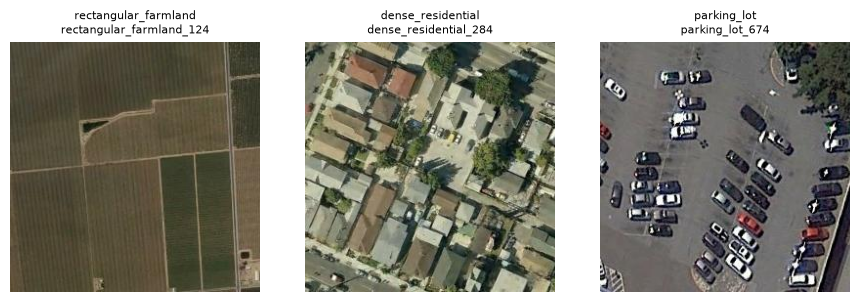

In [9]:
def show_image_batch(batch, n=3):
    n = min(n, len(batch["images"]))

    plt.figure(figsize=(3 * n, 3))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(batch["images"][i])
        plt.axis("off")

        title = f"{batch['class_names'][i]}\n{batch['image_ids'][i]}"
        plt.title(title, fontsize=8)

    plt.tight_layout()
    plt.show()


show_image_batch(batch, n=3)

# Part 1 — Zero-Shot Image Classification with CLIP

In this part, CLIP is used for zero-shot classification on the full RESISC45 test split.

The model is not fine-tuned.  
Instead, each class name is converted into a text prompt, and CLIP predicts the class whose text embedding is most similar to the image embedding.

This part includes prompt construction, text and image encoding, similarity computation, Top-1 accuracy, Recall@5, per-class accuracy, confusion analysis, and visual inspection of predictions.

## 1.1 Define the canonical zero-shot prompt

Each class is represented by one text prompt.

Because RESISC45 contains satellite and aerial images, the prompt is written in a remote-sensing style:

`a satellite image of a {class_name}`

In [10]:
CANONICAL_PROMPT_TEMPLATE = "a satellite image of a {}"


def build_zero_shot_prompts(class_names_clean, template):
    return [
        template.format(class_name)
        for class_name in class_names_clean
    ]


zero_shot_prompts = build_zero_shot_prompts(
    class_names_clean=class_names_clean,
    template=CANONICAL_PROMPT_TEMPLATE,
)

print("Number of classes:", len(class_names_clean))
print("Number of prompts:", len(zero_shot_prompts))
print("Prompt template:", CANONICAL_PROMPT_TEMPLATE)

Number of classes: 45
Number of prompts: 45
Prompt template: a satellite image of a {}


## 1.2 Build a zero-shot CLIP classifier

This class implements the main zero-shot classification steps:

1. encode text prompts,
2. encode image batches,
3. normalize embeddings,
4. compute image-text similarities,
5. predict the most similar class.

In [11]:
class ZeroShotCLIPClassifier:
    """A zero-shot CLIP classifier based on normalized image/text features."""

    def __init__(self, model, processor, class_names, class_names_clean, device):
        self.model = model
        self.processor = processor
        self.class_names = list(class_names)
        self.class_names_clean = list(class_names_clean)
        self.device = torch.device(device)
        self.text_features = None
        self.prompts = None

    @property
    def logit_scale(self):
        return self.model.logit_scale.exp().clamp(max=100.0)

    def build_prompts(self, template):
        if "{}" not in template:
            raise ValueError("The prompt template must contain a '{}' placeholder.")

        self.prompts = [
            template.format(class_name)
            for class_name in self.class_names_clean
        ]
        return self.prompts

    def move_inputs_to_device(self, inputs):
        return {
            key: value.to(self.device) if torch.is_tensor(value) else value
            for key, value in inputs.items()
        }

    @torch.no_grad()
    def encode_text_prompts(self, prompts, batch_size=64):
        self.model.eval()
        feature_batches = []

        for start in range(0, len(prompts), batch_size):
            prompt_batch = prompts[start:start + batch_size]
            inputs = self.processor(
                text=prompt_batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=77,
            )
            inputs = self.move_inputs_to_device(inputs)
            features = self.model.get_text_features(
                input_ids=inputs["input_ids"],
                attention_mask=inputs.get("attention_mask"),
            )
            feature_batches.append(F.normalize(features, dim=-1))

        self.prompts = list(prompts)
        self.text_features = torch.cat(feature_batches, dim=0)
        return self.text_features

    @torch.no_grad()
    def encode_image_batch(self, images):
        self.model.eval()
        inputs = self.processor(
            images=images,
            return_tensors="pt",
        )
        inputs = self.move_inputs_to_device(inputs)
        features = self.model.get_image_features(
            pixel_values=inputs["pixel_values"],
        )
        return F.normalize(features, dim=-1)

    @torch.no_grad()
    def predict_image_batch(self, images, top_k=5):
        if self.text_features is None:
            raise RuntimeError(
                "Text features are missing. Run encode_text_prompts first."
            )

        image_features = self.encode_image_batch(images)
        logits = self.logit_scale * image_features @ self.text_features.T
        probabilities = logits.softmax(dim=-1)
        predictions = probabilities.argmax(dim=-1)

        effective_k = min(top_k, probabilities.shape[1])
        top_probabilities, top_indices = probabilities.topk(
            effective_k,
            dim=-1,
        )

        return {
            "image_features": image_features,
            "logits": logits,
            "probabilities": probabilities,
            "predictions": predictions,
            "top_indices": top_indices,
            "top_probabilities": top_probabilities,
        }


## 1.3 Initialize the classifier and encode text prompts

This cell creates the zero-shot classifier and encodes all class prompts once.

The resulting text embeddings are reused for all image batches during evaluation.

In [12]:
zero_shot_classifier = ZeroShotCLIPClassifier(
    model=model,
    processor=processor,
    class_names=class_names,
    class_names_clean=class_names_clean,
    device=DEVICE,
)

zero_shot_prompts = zero_shot_classifier.build_prompts(
    template=CANONICAL_PROMPT_TEMPLATE,
)

text_features = zero_shot_classifier.encode_text_prompts(
    prompts=zero_shot_prompts,
    batch_size=64,
)

print("Text features shape:", text_features.shape)
print("CLIP logit scale:", float(zero_shot_classifier.logit_scale.detach().cpu()))

Text features shape: torch.Size([45, 768])
CLIP logit scale: 100.0


## 1.4 Evaluate zero-shot classification on the test split

This cell evaluates CLIP on the full test split.

For each image, it stores the true label, predicted label, image embedding, logits, probabilities, and Top-5 predicted classes.

In [13]:
def compute_top1_accuracy(true_labels, predicted_labels):
    true_labels = np.asarray(true_labels)
    predicted_labels = np.asarray(predicted_labels)

    if true_labels.shape != predicted_labels.shape:
        raise ValueError("true_labels and predicted_labels must have equal shapes.")
    if true_labels.size == 0:
        return 0.0

    return float(np.mean(true_labels == predicted_labels))


def compute_recall_at_k(true_labels, top_k_indices, k=5):
    true_labels = np.asarray(true_labels).reshape(-1)
    top_k_indices = np.asarray(top_k_indices)

    if top_k_indices.ndim != 2:
        raise ValueError("top_k_indices must have shape (num_samples, top_k).")
    if len(true_labels) != len(top_k_indices):
        raise ValueError("Inputs must contain the same number of samples.")
    if len(true_labels) == 0:
        return 0.0

    effective_k = min(k, top_k_indices.shape[1])
    hits = (top_k_indices[:, :effective_k] == true_labels[:, None]).any(axis=1)
    return float(hits.mean())


@torch.no_grad()
def evaluate_zero_shot_classifier(classifier, dataloader, top_k=5):
    start_time = time.perf_counter()
    storage = defaultdict(list)
    image_ids = []
    class_names_batchwise = []

    for batch in tqdm(dataloader, desc="Zero-shot evaluation"):
        output = classifier.predict_image_batch(
            batch["images"],
            top_k=top_k,
        )

        for key in [
            "image_features",
            "logits",
            "probabilities",
            "predictions",
            "top_indices",
            "top_probabilities",
        ]:
            storage[key].append(output[key].detach().cpu())

        storage["labels"].append(batch["labels"].detach().cpu())
        image_ids.extend(batch["image_ids"])
        class_names_batchwise.extend(batch["class_names"])

    results = {
        key: torch.cat(value, dim=0)
        for key, value in storage.items()
    }
    results["image_ids"] = image_ids
    results["class_names"] = class_names_batchwise
    results["prompt_templates"] = list(classifier.prompts)

    labels_np = results["labels"].numpy()
    predictions_np = results["predictions"].numpy()
    top_indices_np = results["top_indices"].numpy()

    results["top1_accuracy"] = compute_top1_accuracy(
        labels_np,
        predictions_np,
    )
    results["recall_at_5"] = compute_recall_at_k(
        labels_np,
        top_indices_np,
        k=min(5, top_k),
    )
    results["elapsed_time"] = time.perf_counter() - start_time
    return results


def build_prediction_dataframe(results, class_names, prompts):
    labels = results["labels"].detach().cpu().numpy().astype(int)
    predictions = results["predictions"].detach().cpu().numpy().astype(int)
    probabilities = results["probabilities"].detach().cpu().numpy()
    top_indices = results["top_indices"].detach().cpu().numpy().astype(int)
    top_probabilities = (
        results["top_probabilities"].detach().cpu().numpy()
    )

    rows = []
    for row_index, (true_label, pred_label) in enumerate(
        zip(labels, predictions)
    ):
        row = {
            "row_index": row_index,
            "image_id": results["image_ids"][row_index],
            "true_label": int(true_label),
            "true_class": class_names[int(true_label)],
            "pred_label": int(pred_label),
            "pred_class": class_names[int(pred_label)],
            "pred_prompt": prompts[int(pred_label)],
            "confidence": float(probabilities[row_index, pred_label]),
            "correct": bool(true_label == pred_label),
        }

        for rank, class_index in enumerate(top_indices[row_index], start=1):
            row[f"top{rank}_label"] = int(class_index)
            row[f"top{rank}_class"] = class_names[int(class_index)]
            row[f"top{rank}_probability"] = float(
                top_probabilities[row_index, rank - 1]
            )

        rows.append(row)

    return pd.DataFrame(rows)


zero_shot_results = evaluate_zero_shot_classifier(
    classifier=zero_shot_classifier,
    dataloader=test_loader,
    top_k=5,
)

base_full_test_results = zero_shot_results

df_zero_shot_predictions = build_prediction_dataframe(
    results=zero_shot_results,
    class_names=class_names,
    prompts=zero_shot_prompts,
)

true_labels_np = zero_shot_results["labels"].numpy()
pred_labels_np = zero_shot_results["predictions"].numpy()
top_indices_np = zero_shot_results["top_indices"].numpy()

zero_shot_accuracy = zero_shot_results["top1_accuracy"]
zero_shot_recall_at_5 = zero_shot_results["recall_at_5"]

print("Zero-shot classification results")
print("--------------------------------")
print("Evaluation split: full test")
print("Prompt template:", CANONICAL_PROMPT_TEMPLATE)
print("Images:", len(true_labels_np))
print("Classes:", num_classes)
print(f"Top-1 Accuracy: {zero_shot_accuracy:.4f}")
print(f"Recall@5:       {zero_shot_recall_at_5:.4f}")
print(f"Elapsed time:   {zero_shot_results['elapsed_time']:.2f} seconds")

print("\nStored objects for later parts:")
print("- zero_shot_results")
print("- base_full_test_results")
print("- df_zero_shot_predictions")


Zero-shot evaluation: 100%|██████████| 394/394 [11:14<00:00,  1.71s/it]

Zero-shot classification results
--------------------------------
Evaluation split: full test
Prompt template: a satellite image of a {}
Images: 6300
Classes: 45
Top-1 Accuracy: 0.6779
Recall@5:       0.9470
Elapsed time:   674.15 seconds

Stored objects for later parts:
- zero_shot_results
- base_full_test_results
- df_zero_shot_predictions


## 1.5 Per-class accuracy

This cell computes accuracy for each class separately.

For single-label classification, per-class accuracy is equivalent to per-class recall.

In [14]:
def compute_per_class_accuracy(prediction_df, class_names):
    required = {"true_label", "pred_label"}
    missing = required - set(prediction_df.columns)
    if missing:
        raise KeyError(f"Missing prediction columns: {sorted(missing)}")

    rows = []
    for class_id, class_name in enumerate(class_names):
        class_rows = prediction_df[
            prediction_df["true_label"].astype(int) == class_id
        ]
        total = len(class_rows)
        correct = int(
            (
                class_rows["true_label"].astype(int)
                == class_rows["pred_label"].astype(int)
            ).sum()
        )

        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "total": total,
            "correct": correct,
            "accuracy": correct / total if total else np.nan,
        })

    return pd.DataFrame(rows)


df_per_class_accuracy = compute_per_class_accuracy(
    prediction_df=df_zero_shot_predictions,
    class_names=class_names,
)

df_per_class_accuracy_sorted = df_per_class_accuracy.sort_values(
    by="accuracy",
    ascending=False,
).reset_index(drop=True)

display(df_per_class_accuracy_sorted)

print("Best classes:")
display(df_per_class_accuracy_sorted.head(5))

print("Worst classes:")
display(df_per_class_accuracy_sorted.tail(5))


,class_id,class_name,total,correct,accuracy
0,15,golf_course,122,122,1.000000
1,28,parking_lot,135,132,0.977778
2,31,rectangular_farmland,135,132,0.977778
3,33,roundabout,134,129,0.962687
4,17,harbor,142,136,0.957746
5,24,mobile_home_park,164,157,0.957317
6,21,lake,131,122,0.931298
7,4,beach,130,120,0.923077
8,39,stadium,142,131,0.922535
9,40,storage_tank,137,126,0.919708


Best classes:


,class_id,class_name,total,correct,accuracy
0,15,golf_course,122,122,1.000000
1,28,parking_lot,135,132,0.977778
2,31,rectangular_farmland,135,132,0.977778
3,33,roundabout,134,129,0.962687
4,17,harbor,142,136,0.957746


Worst classes:


,class_id,class_name,total,correct,accuracy
40,22,meadow,130,31,0.238462
41,23,medium_residential,147,20,0.136054
42,25,mountain,115,15,0.130435
43,38,sparse_residential,130,8,0.061538
44,42,terrace,127,1,0.007874


## 1.6 Confusion matrix

This cell plots the normalized confusion matrix.

It shows which true classes are correctly predicted and which classes are confused with each other.

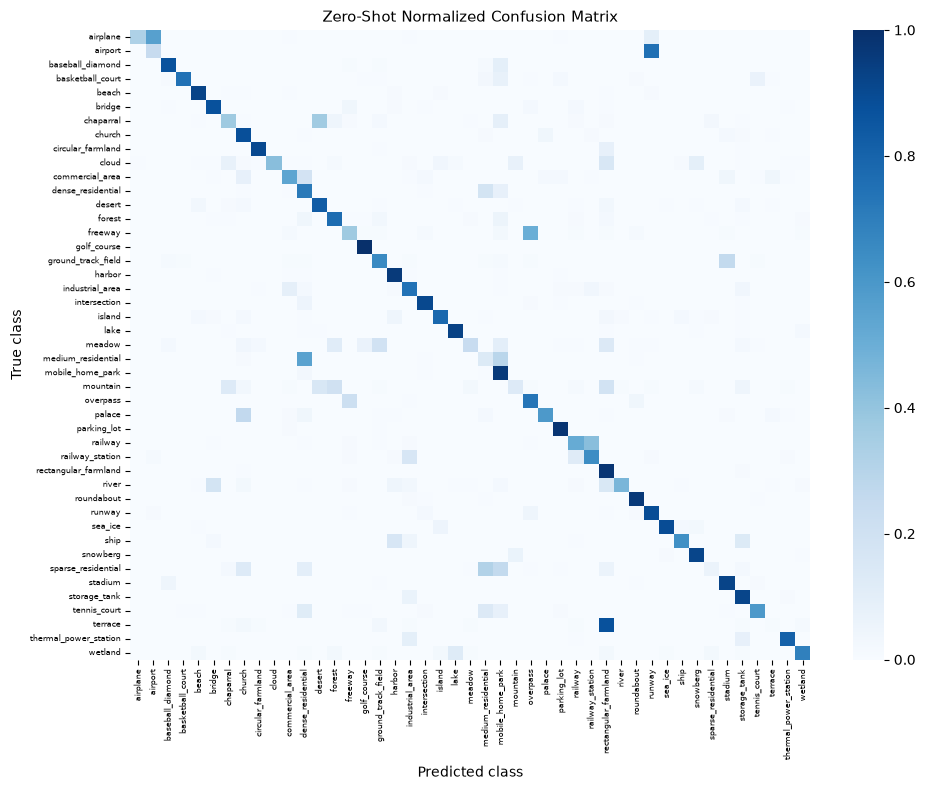

In [15]:
cm = confusion_matrix(
    true_labels_np,
    pred_labels_np,
    labels=list(range(num_classes)),
)

cm_normalized = cm.astype(np.float32) / cm.sum(axis=1, keepdims=True)
cm_normalized = np.nan_to_num(cm_normalized)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False,
    cbar=True,
    vmin=0,
    vmax=1,
)

plt.title("Zero-Shot Normalized Confusion Matrix", fontsize=11)
plt.xlabel("Predicted class")
plt.ylabel("True class")

plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

## 1.7 Most frequent confusion pairs

This cell lists the most common wrong predictions.

In [16]:
def get_top_confusions(confusion_matrix_array, class_names, top_n=15):
    matrix = np.asarray(confusion_matrix_array)
    expected_shape = (len(class_names), len(class_names))

    if matrix.shape != expected_shape:
        raise ValueError(
            f"Expected confusion matrix shape {expected_shape}, got {matrix.shape}."
        )

    rows = []
    for true_id in range(len(class_names)):
        for pred_id in range(len(class_names)):
            if true_id == pred_id:
                continue

            count = int(matrix[true_id, pred_id])
            if count > 0:
                rows.append({
                    "true_class_id": true_id,
                    "true_class": class_names[true_id],
                    "pred_class_id": pred_id,
                    "pred_class": class_names[pred_id],
                    "count": count,
                })

    if not rows:
        return pd.DataFrame(columns=[
            "true_class_id",
            "true_class",
            "pred_class_id",
            "pred_class",
            "count",
        ])

    return (
        pd.DataFrame(rows)
        .sort_values(
            ["count", "true_class", "pred_class"],
            ascending=[False, True, True],
        )
        .head(top_n)
        .reset_index(drop=True)
    )


df_top_confusions = get_top_confusions(
    confusion_matrix_array=cm,
    class_names=class_names,
    top_n=15,
)

display(df_top_confusions)


,true_class_id,true_class,pred_class_id,pred_class,count
0,1,airport,34,runway,122
1,42,terrace,31,rectangular_farmland,111
2,0,airplane,1,airport,95
3,23,medium_residential,11,dense_residential,81
4,29,railway,30,railway_station,60
5,14,freeway,26,overpass,59
6,6,chaparral,12,desert,48
7,23,medium_residential,24,mobile_home_park,42
8,38,sparse_residential,23,medium_residential,41
9,27,palace,7,church,37


## 1.8 Visualize confident correct predictions

This cell shows examples where CLIP predicted the correct class with high confidence.

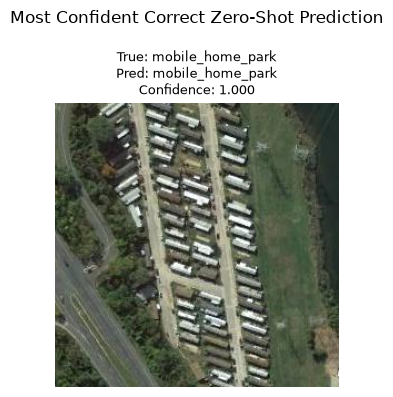

In [17]:
def show_prediction_examples(prediction_df, hf_dataset, title, n=1):
    if n <= 0 or len(prediction_df) == 0:
        print(f"No examples available for: {title}")
        return

    examples = prediction_df.head(n)
    figure, axes = plt.subplots(
        1,
        len(examples),
        figsize=(4 * len(examples), 4),
        squeeze=False,
    )

    for axis, (_, row) in zip(axes.ravel(), examples.iterrows()):
        dataset_index = int(row["row_index"])
        image = hf_dataset[dataset_index]["image"].convert("RGB")
        axis.imshow(image)
        axis.axis("off")
        axis.set_title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['pred_class']}\n"
            f"Confidence: {row['confidence']:.3f}",
            fontsize=9,
        )

    figure.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


df_confident_correct = (
    df_zero_shot_predictions[df_zero_shot_predictions["correct"]]
    .sort_values(by="confidence", ascending=False)
)

show_prediction_examples(
    prediction_df=df_confident_correct,
    hf_dataset=test_full_ds,
    title="Most Confident Correct Zero-Shot Prediction",
    n=1,
)


## 1.9 Visualize confident incorrect predictions

This cell shows high-confidence mistakes.

These examples help identify failure cases of zero-shot CLIP on remote-sensing images.

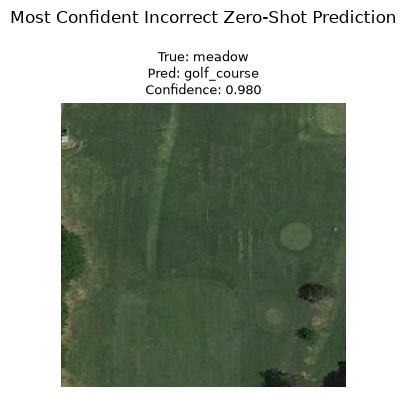

In [18]:
df_confident_errors = (
    df_zero_shot_predictions[~df_zero_shot_predictions["correct"]]
    .sort_values(by="confidence", ascending=False)
)

show_prediction_examples(
    prediction_df=df_confident_errors,
    hf_dataset=test_full_ds,
    title="Most Confident Incorrect Zero-Shot Prediction",
    n=1,
)

# Part 2 — Embedding Extraction and Visualization

In this part, we analyze the CLIP image embeddings from Part 1.

The goal is to study how RESISC45 images are organized in the CLIP embedding space before fine-tuning.

This part includes embedding loading, normalization, PCA, t-SNE, class centroid analysis, class compactness, and nearest-neighbor consistency.

## 2.1 Section configuration

This cell defines the main settings for PCA, t-SNE, and nearest-neighbor analysis.

In [19]:
PCA_N_COMPONENTS_FOR_TSNE = 50
TSNE_N_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1000

NEAREST_NEIGHBORS_K = 10

print("Part 2 configuration")
print("--------------------")
print("PCA components before t-SNE:", PCA_N_COMPONENTS_FOR_TSNE)
print("t-SNE perplexity:", TSNE_PERPLEXITY)
print("Nearest neighbors k:", NEAREST_NEIGHBORS_K)

Part 2 configuration
--------------------
PCA components before t-SNE: 50
t-SNE perplexity: 30
Nearest neighbors k: 10


## 2.2 Load image embeddings

This cell loads the image embeddings saved during zero-shot evaluation in Part 1.


In [20]:
def get_embeddings_from_part1():
    if "zero_shot_results" not in globals():
        raise RuntimeError(
            "zero_shot_results was not found. Run Part 1 before Part 2."
        )

    required_keys = [
        "image_features",
        "labels",
        "image_ids",
        "predictions",
        "probabilities",
    ]

    missing_keys = [
        key
        for key in required_keys
        if key not in zero_shot_results
    ]

    if missing_keys:
        raise KeyError(f"Missing keys in zero_shot_results: {missing_keys}")

    return {
        "image_features": zero_shot_results["image_features"],
        "labels": zero_shot_results["labels"],
        "image_ids": zero_shot_results["image_ids"],
        "source": "part1_zero_shot_results",
    }


embedding_output = get_embeddings_from_part1()

image_embeddings = embedding_output["image_features"]
embedding_labels = embedding_output["labels"]
embedding_image_ids = embedding_output["image_ids"]

print("Embedding source:", embedding_output["source"])
print("Image embeddings shape:", image_embeddings.shape)
print("Labels shape:", embedding_labels.shape)
print("Number of image ids:", len(embedding_image_ids))

Embedding source: part1_zero_shot_results
Image embeddings shape: torch.Size([6300, 768])
Labels shape: torch.Size([6300])
Number of image ids: 6300


## 2.3 Build the embedding dataframe

This cell creates a dataframe that connects each embedding to its image ID, true class, predicted class, confidence, and correctness.

In [21]:
def build_embedding_dataframe(labels, image_ids, class_names):
    labels_np = labels.detach().cpu().numpy().astype(int)

    rows = []

    for row_index, label_id in enumerate(labels_np):
        rows.append({
            "row_index": row_index,
            "image_id": image_ids[row_index],
            "label_id": int(label_id),
            "class_name": class_names[int(label_id)],
        })

    return pd.DataFrame(rows)


df_embeddings = build_embedding_dataframe(
    labels=embedding_labels,
    image_ids=embedding_image_ids,
    class_names=class_names,
)

if "df_zero_shot_predictions" not in globals():
    raise RuntimeError(
        "df_zero_shot_predictions was not found. Run Part 1 before Part 2."
    )

prediction_columns = [
    "row_index",
    "pred_label",
    "pred_class",
    "confidence",
    "correct",
]

df_embeddings = df_embeddings.merge(
    df_zero_shot_predictions[prediction_columns],
    on="row_index",
    how="left",
)

display(df_embeddings.head())

print("Embedding dataframe shape:", df_embeddings.shape)
print("Number of unique classes:", df_embeddings["class_name"].nunique())
print("Zero-shot accuracy in dataframe:", df_embeddings["correct"].mean())

,row_index,image_id,label_id,class_name,pred_label,pred_class,confidence,correct
0,0,rectangular_farmland_124,31,rectangular_farmland,31,rectangular_farmland,0.829204,True
1,1,dense_residential_284,11,dense_residential,11,dense_residential,0.553165,True
2,2,parking_lot_674,28,parking_lot,28,parking_lot,0.996339,True
3,3,thermal_power_station_536,43,thermal_power_station,43,thermal_power_station,0.995826,True
4,4,tennis_court_162,41,tennis_court,41,tennis_court,0.903114,True


Embedding dataframe shape: (6300, 8)
Number of unique classes: 45
Zero-shot accuracy in dataframe: 0.677936507936508


## 2.4 Convert embeddings to NumPy and normalize

CLIP embeddings are compared with cosine similarity.

Therefore, this cell converts embeddings to NumPy and applies L2-normalization.

In [22]:
def l2_normalize_numpy(array, eps=1e-12):
    array = np.asarray(array, dtype=np.float32)
    if array.ndim != 2:
        raise ValueError("array must have shape (num_samples, embedding_dim).")

    norms = np.linalg.norm(array, axis=1, keepdims=True)
    return array / np.maximum(norms, eps)


X_clip = image_embeddings.detach().cpu().numpy().astype(np.float32)
y_labels = embedding_labels.detach().cpu().numpy().astype(int)

X_clip_norm = l2_normalize_numpy(X_clip)

norms = np.linalg.norm(X_clip_norm, axis=1)

print("Embedding matrix:", X_clip_norm.shape)
print("Minimum norm:", norms.min())
print("Maximum norm:", norms.max())
print("Mean norm:", norms.mean())


Embedding matrix: (6300, 768)
Minimum norm: 0.9999999
Maximum norm: 1.0000001
Mean norm: 1.0


## 2.5 Dimensionality reduction helper class

This helper class applies PCA and t-SNE to high-dimensional CLIP embeddings.

PCA is used for linear projection, while t-SNE is used for local neighborhood visualization.

In [23]:
class EmbeddingProjector:
    """A helper for reproducible PCA and t-SNE projection."""

    def __init__(self, random_state=42):
        self.random_state = random_state
        self.pca_model = None
        self.tsne_model = None

    def fit_pca(self, embeddings, n_components=50):
        embeddings = np.asarray(embeddings)
        max_components = min(embeddings.shape[0], embeddings.shape[1])
        if not 1 <= n_components <= max_components:
            raise ValueError(
                f"n_components must be in [1, {max_components}]."
            )

        self.pca_model = PCA(
            n_components=n_components,
            random_state=self.random_state,
        )
        return self.pca_model.fit_transform(embeddings)

    def fit_tsne(self, embeddings, perplexity=30, max_iter=1000):
        embeddings = np.asarray(embeddings)
        if len(embeddings) < 2:
            raise ValueError("t-SNE requires at least two samples.")

        effective_perplexity = min(float(perplexity), len(embeddings) - 1)
        self.tsne_model = TSNE(
            n_components=2,
            perplexity=effective_perplexity,
            max_iter=max_iter,
            init="pca",
            learning_rate="auto",
            random_state=self.random_state,
        )
        return self.tsne_model.fit_transform(embeddings)


## 2.6 Compute PCA and t-SNE projections

This cell first applies PCA and then runs t-SNE on the PCA features.


In [24]:
projector = EmbeddingProjector(
    random_state=RANDOM_SEED,
)

X_pca = projector.fit_pca(
    embeddings=X_clip_norm,
    n_components=PCA_N_COMPONENTS_FOR_TSNE,
)

explained_variance = projector.pca_model.explained_variance_ratio_
cumulative_explained_variance = explained_variance.cumsum()

print("PCA output shape:", X_pca.shape)
print(f"Explained variance by first component: {explained_variance[0]:.4f}")
print(f"Cumulative explained variance: {cumulative_explained_variance[-1]:.4f}")

X_tsne = projector.fit_tsne(
    embeddings=X_pca,
    perplexity=TSNE_PERPLEXITY,
    max_iter=TSNE_MAX_ITER,
)

print("t-SNE output shape:", X_tsne.shape)

PCA output shape: (6300, 50)
Explained variance by first component: 0.0946
Cumulative explained variance: 0.7318
t-SNE output shape: (6300, 2)


## 2.7 Add projection coordinates to the dataframe

This cell adds PCA and t-SNE coordinates to the embedding dataframe for later visualization and analysis.

In [25]:
df_embeddings["pca_1"] = X_pca[:, 0]
df_embeddings["pca_2"] = X_pca[:, 1]

df_embeddings["tsne_1"] = X_tsne[:, 0]
df_embeddings["tsne_2"] = X_tsne[:, 1]

display(df_embeddings[[
    "row_index",
    "image_id",
    "class_name",
    "pred_class",
    "confidence",
    "correct",
    "pca_1",
    "pca_2",
    "tsne_1",
    "tsne_2",
]].head())

,row_index,image_id,class_name,pred_class,confidence,correct,pca_1,pca_2,tsne_1,tsne_2
0,0,rectangular_farmland_124,rectangular_farmland,rectangular_farmland,0.829204,True,0.037918,0.131267,-4.308572,58.476669
1,1,dense_residential_284,dense_residential,dense_residential,0.553165,True,-0.242994,0.100804,-29.945766,21.049030
2,2,parking_lot_674,parking_lot,parking_lot,0.996339,True,-0.180339,0.036683,-40.204987,4.867519
3,3,thermal_power_station_536,thermal_power_station,thermal_power_station,0.995826,True,0.118043,-0.258998,-16.280083,-57.837898
4,4,tennis_court_162,tennis_court,tennis_court,0.903114,True,-0.224633,0.147558,-50.887142,16.893993


## 2.8 Plot PCA projection by class

This cell visualizes the global structure of CLIP image embeddings using PCA.

Each point represents one test image.

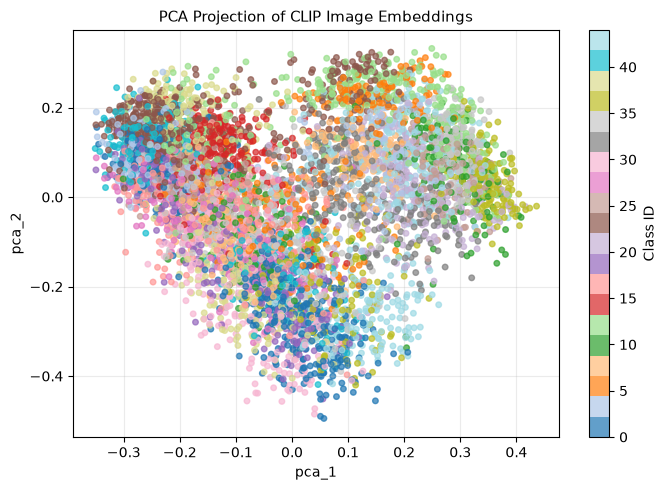

In [26]:
def plot_2d_projection_by_label(
    dataframe,
    x_col,
    y_col,
    label_col,
    title,
    figsize=(7, 5),
    point_size=16,
    alpha=0.70,
):
    plt.figure(figsize=figsize)

    scatter = plt.scatter(
        dataframe[x_col],
        dataframe[y_col],
        c=dataframe[label_col],
        cmap="tab20",
        s=point_size,
        alpha=alpha,
    )

    plt.title(title, fontsize=11)
    plt.xlabel(x_col)
    plt.ylabel(y_col)

    cbar = plt.colorbar(scatter)
    cbar.set_label("Class ID")

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_2d_projection_by_label(
    dataframe=df_embeddings,
    x_col="pca_1",
    y_col="pca_2",
    label_col="label_id",
    title="PCA Projection of CLIP Image Embeddings",
)

## 2.9 Plot t-SNE projection by class

This cell visualizes local neighborhoods in the CLIP embedding space using t-SNE.

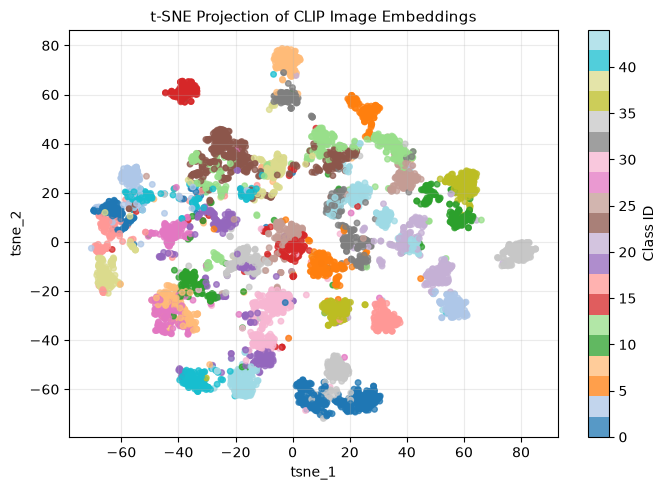

In [27]:
plot_2d_projection_by_label(
    dataframe=df_embeddings,
    x_col="tsne_1",
    y_col="tsne_2",
    label_col="label_id",
    title="t-SNE Projection of CLIP Image Embeddings",
    figsize=(7, 5),
    point_size=16,
    alpha=0.75,
)

## 2.10 Plot correct and incorrect zero-shot predictions in t-SNE space

This cell shows where correct and incorrect zero-shot predictions appear in the t-SNE embedding space.

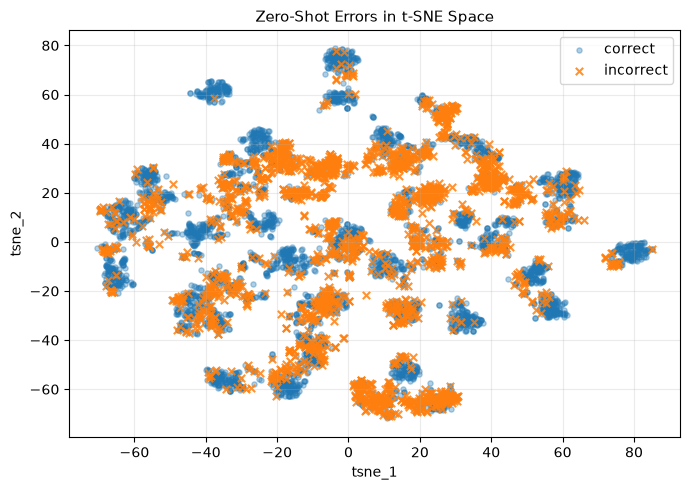

In [28]:
def plot_correctness_on_tsne(dataframe):
    if "correct" not in dataframe.columns:
        print("Prediction correctness is not available.")
        return

    correct_df = dataframe[dataframe["correct"] == True]
    error_df = dataframe[dataframe["correct"] == False]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        correct_df["tsne_1"],
        correct_df["tsne_2"],
        s=14,
        alpha=0.35,
        label="correct",
    )

    plt.scatter(
        error_df["tsne_1"],
        error_df["tsne_2"],
        s=28,
        alpha=0.85,
        marker="x",
        label="incorrect",
    )

    plt.title("Zero-Shot Errors in t-SNE Space", fontsize=11)
    plt.xlabel("tsne_1")
    plt.ylabel("tsne_2")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_correctness_on_tsne(df_embeddings)

## 2.11 Supervised embedding analyzer

This cell analyzes the embedding space using class labels.

It computes class centroids, class compactness, closest class pairs, and nearest-neighbor consistency.

In [29]:
def compute_class_centroids(embeddings, labels, class_names):
    embeddings = l2_normalize_numpy(embeddings)
    labels = np.asarray(labels, dtype=int)
    centroids = []
    rows = []

    for class_id, class_name in enumerate(class_names):
        class_embeddings = embeddings[labels == class_id]
        if len(class_embeddings) == 0:
            raise ValueError(f"No embeddings were found for class {class_id}.")

        centroid = class_embeddings.mean(axis=0)
        centroid = centroid / max(np.linalg.norm(centroid), 1e-12)
        cosine_similarities = class_embeddings @ centroid
        cosine_distances = 1.0 - cosine_similarities

        centroids.append(centroid)
        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "num_samples": len(class_embeddings),
            "mean_cosine_similarity": float(cosine_similarities.mean()),
            "mean_cosine_distance": float(cosine_distances.mean()),
            "std_cosine_distance": float(cosine_distances.std()),
        })

    return np.vstack(centroids).astype(np.float32), pd.DataFrame(rows)


def compute_closest_centroid_pairs(centroids, class_names, top_n=10):
    centroids = l2_normalize_numpy(centroids)
    similarities = centroids @ centroids.T
    rows = []

    for first_id in range(len(class_names)):
        for second_id in range(first_id + 1, len(class_names)):
            similarity = float(similarities[first_id, second_id])
            rows.append({
                "class_a_id": first_id,
                "class_a": class_names[first_id],
                "class_b_id": second_id,
                "class_b": class_names[second_id],
                "cosine_similarity": similarity,
                "cosine_distance": 1.0 - similarity,
            })

    return (
        pd.DataFrame(rows)
        .sort_values("cosine_distance", ascending=True)
        .head(top_n)
        .reset_index(drop=True)
    )


def compute_nearest_neighbor_consistency(embeddings, labels, class_names, k=10):
    embeddings = l2_normalize_numpy(embeddings)
    labels = np.asarray(labels, dtype=int)
    if len(embeddings) < 2:
        raise ValueError("At least two embeddings are required.")

    effective_k = min(k, len(embeddings) - 1)
    neighbor_model = NearestNeighbors(
        n_neighbors=effective_k + 1,
        metric="cosine",
        algorithm="brute",
    )
    neighbor_model.fit(embeddings)
    _, neighbor_indices = neighbor_model.kneighbors(embeddings)
    neighbor_indices = neighbor_indices[:, 1:]

    neighbor_labels = labels[neighbor_indices]
    same_class_ratio = (neighbor_labels == labels[:, None]).mean(axis=1)

    point_df = pd.DataFrame({
        "row_index": np.arange(len(labels)),
        "same_class_neighbor_ratio": same_class_ratio,
    })

    rows = []
    for class_id, class_name in enumerate(class_names):
        values = same_class_ratio[labels == class_id]
        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "num_samples": len(values),
            "mean_same_class_neighbor_ratio": float(values.mean()),
            "std_same_class_neighbor_ratio": float(values.std()),
        })

    return pd.DataFrame(rows), point_df


class_centroids, df_class_compactness = compute_class_centroids(
    embeddings=X_clip_norm,
    labels=y_labels,
    class_names=class_names,
)

df_class_compactness_sorted = df_class_compactness.sort_values(
    by="mean_cosine_distance",
    ascending=True,
).reset_index(drop=True)

df_centroid_distances = compute_closest_centroid_pairs(
    centroids=class_centroids,
    class_names=class_names,
    top_n=10,
)

df_nn_consistency, df_point_nn = compute_nearest_neighbor_consistency(
    embeddings=X_clip_norm,
    labels=y_labels,
    class_names=class_names,
    k=NEAREST_NEIGHBORS_K,
)

df_nn_consistency_sorted = df_nn_consistency.sort_values(
    by="mean_same_class_neighbor_ratio",
    ascending=False,
).reset_index(drop=True)

df_embeddings = df_embeddings.merge(
    df_point_nn,
    on="row_index",
    how="left",
)

print("Most compact classes:")
display(df_class_compactness_sorted.head(5))

print("Least compact classes:")
display(df_class_compactness_sorted.tail(5))

print("Closest class centroid pairs:")
display(df_centroid_distances)

print("Highest nearest-neighbor consistency:")
display(df_nn_consistency_sorted.head(5))

print("Lowest nearest-neighbor consistency:")
display(df_nn_consistency_sorted.tail(5))


Most compact classes:


,class_id,class_name,num_samples,mean_cosine_similarity,mean_cosine_distance,std_cosine_distance
0,8,circular_farmland,146,0.936135,0.063865,0.032178
1,15,golf_course,122,0.920086,0.079914,0.031601
2,35,sea_ice,151,0.915295,0.084705,0.039251
3,6,chaparral,132,0.912734,0.087266,0.042382
4,26,overpass,150,0.911416,0.088584,0.030726


Least compact classes:


,class_id,class_name,num_samples,mean_cosine_similarity,mean_cosine_distance,std_cosine_distance
40,21,lake,131,0.863187,0.136813,0.032980
41,20,island,139,0.858553,0.141447,0.051030
42,39,stadium,142,0.853642,0.146358,0.035012
43,7,church,143,0.849415,0.150585,0.036604
44,27,palace,140,0.840078,0.159922,0.035060


Closest class centroid pairs:


,class_a_id,class_a,class_b_id,class_b,cosine_similarity,cosine_distance
0,7,church,27,palace,0.962240,0.037760
1,14,freeway,26,overpass,0.961148,0.038852
2,11,dense_residential,23,medium_residential,0.959709,0.040291
3,29,railway,30,railway_station,0.955833,0.044167
4,13,forest,22,meadow,0.954504,0.045496
5,23,medium_residential,24,mobile_home_park,0.952991,0.047009
6,31,rectangular_farmland,42,terrace,0.942027,0.057973
7,23,medium_residential,38,sparse_residential,0.939768,0.060232
8,3,basketball_court,41,tennis_court,0.938157,0.061843
9,18,industrial_area,30,railway_station,0.937936,0.062064


Highest nearest-neighbor consistency:


,class_id,class_name,num_samples,mean_same_class_neighbor_ratio,std_same_class_neighbor_ratio
0,35,sea_ice,151,0.995364,0.031175
1,15,golf_course,122,0.986885,0.084883
2,6,chaparral,132,0.982576,0.066851
3,37,snowberg,159,0.974843,0.085391
4,17,harbor,142,0.968310,0.128024


Lowest nearest-neighbor consistency:


,class_id,class_name,num_samples,mean_same_class_neighbor_ratio,std_same_class_neighbor_ratio
40,23,medium_residential,147,0.668027,0.244389
41,14,freeway,118,0.650847,0.285154
42,7,church,143,0.645455,0.265953
43,30,railway_station,154,0.635065,0.287744
44,27,palace,140,0.575714,0.276165


## 2.12 Build class centroid projection

This cell projects class centroids into two dimensions with PCA.

The plot gives a compact view of high-level relationships between classes.

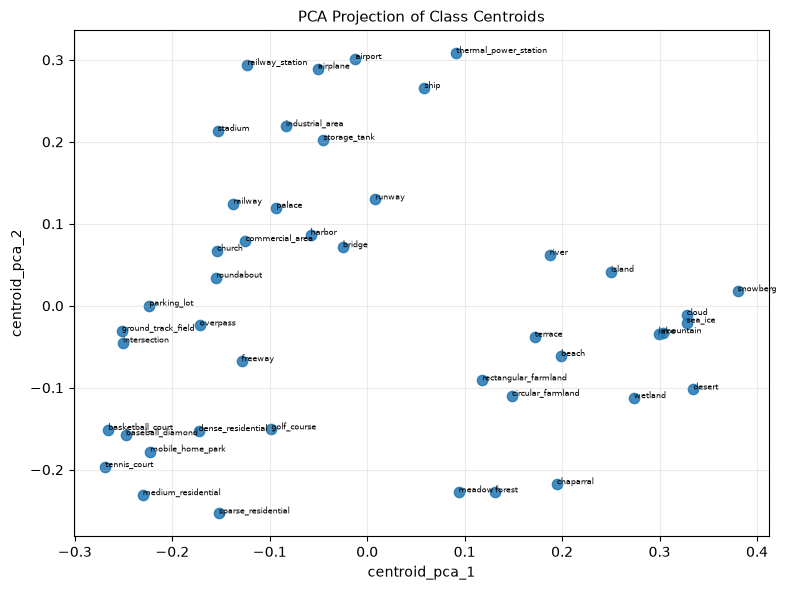

In [30]:
centroid_projector = EmbeddingProjector(
    random_state=RANDOM_SEED,
)

centroid_pca = centroid_projector.fit_pca(
    embeddings=class_centroids,
    n_components=2,
)

df_centroids = pd.DataFrame({
    "class_id": np.arange(len(class_names)),
    "class_name": class_names,
    "centroid_pca_1": centroid_pca[:, 0],
    "centroid_pca_2": centroid_pca[:, 1],
})

plt.figure(figsize=(8, 6))

plt.scatter(
    df_centroids["centroid_pca_1"],
    df_centroids["centroid_pca_2"],
    s=55,
    alpha=0.85,
)

for _, row in df_centroids.iterrows():
    plt.text(
        row["centroid_pca_1"],
        row["centroid_pca_2"],
        row["class_name"],
        fontsize=6,
    )

plt.title("PCA Projection of Class Centroids", fontsize=11)
plt.xlabel("centroid_pca_1")
plt.ylabel("centroid_pca_2")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Part 3 — Prompt Engineering for Zero-Shot Classification

In this part, we study how prompt wording affects CLIP zero-shot classification.

The image embeddings stay fixed, and only the text prompts are changed.  
This isolates the effect of the text side of CLIP.

This part includes single-prompt evaluation, per-class prompt sensitivity, and prompt ensembling.

## 3.1 Define prompt templates

This cell defines several prompt templates for RESISC45 classes.

The prompts include generic image descriptions and remote-sensing-specific descriptions.

In [31]:
PROMPT_BANK = {
    "minimal": "{}",
    "photo": "a photo of a {}",
    "image": "an image of a {}",
    "satellite_canonical": "a satellite image of a {}",
    "remote_sensing": "a remote sensing image of a {}",
    "aerial": "an aerial image of a {}",
    "overhead": "an overhead view of a {}",
    "high_res_satellite": "a high resolution satellite image of a {}",
    "cropped_satellite": "a cropped satellite image of a {}",
}

PROMPT_GROUPS = {
    "generic_prompts": [
        "minimal",
        "photo",
        "image",
    ],
    "domain_prompts": [
        "satellite_canonical",
        "remote_sensing",
        "aerial",
        "overhead",
    ],
    "strong_domain_prompts": [
        "satellite_canonical",
        "remote_sensing",
        "aerial",
        "high_res_satellite",
        "cropped_satellite",
    ],
}

CANONICAL_PROMPT_ID = "satellite_canonical"

print("Number of prompt templates:", len(PROMPT_BANK))
print("Canonical prompt:", PROMPT_BANK[CANONICAL_PROMPT_ID])

display(
    pd.DataFrame([
        {
            "prompt_id": prompt_id,
            "template": template,
        }
        for prompt_id, template in PROMPT_BANK.items()
    ])
)

Number of prompt templates: 9
Canonical prompt: a satellite image of a {}


,prompt_id,template
0,minimal,{}
1,photo,a photo of a {}
2,image,an image of a {}
3,satellite_canonical,a satellite image of a {}
4,remote_sensing,a remote sensing image of a {}
5,aerial,an aerial image of a {}
6,overhead,an overhead view of a {}
7,high_res_satellite,a high resolution satellite image of a {}
8,cropped_satellite,a cropped satellite image of a {}


## 3.2 Prepare embeddings for prompt evaluation

This cell prepares fixed image embeddings and labels for prompt evaluation.

Using fixed image embeddings makes the experiment faster and focuses only on prompt effects.

In [32]:
def get_prompt_experiment_data():
    if "X_clip_norm" in globals() and "y_labels" in globals():
        return {
            "image_features": X_clip_norm.astype(np.float32),
            "labels": y_labels.astype(int),
            "image_ids": df_embeddings["image_id"].tolist() if "df_embeddings" in globals() else None,
            "source": "part2_normalized_embeddings",
        }

    if "zero_shot_results" in globals():
        image_features = zero_shot_results["image_features"].detach().cpu().numpy().astype(np.float32)
        image_features = l2_normalize_numpy(image_features)

        return {
            "image_features": image_features,
            "labels": zero_shot_results["labels"].detach().cpu().numpy().astype(int),
            "image_ids": zero_shot_results["image_ids"],
            "source": "part1_zero_shot_results",
        }

    raise RuntimeError(
        "No image embeddings were found. Run Part 1 or Part 2 before Part 3."
    )


prompt_data = get_prompt_experiment_data()

prompt_image_features = prompt_data["image_features"]
prompt_labels = prompt_data["labels"]
prompt_image_ids = prompt_data["image_ids"]
prompt_data_source = prompt_data["source"]

print("Prompt experiment data")
print("----------------------")
print("Data source:", prompt_data_source)
print("Image features:", prompt_image_features.shape)
print("Labels:", prompt_labels.shape)
print("Image ids:", len(prompt_image_ids) if prompt_image_ids is not None else None)

Prompt experiment data
----------------------
Data source: part2_normalized_embeddings
Image features: (6300, 768)
Labels: (6300,)
Image ids: 6300


## 3.3 Define a prompt evaluator

This class evaluates zero-shot classification for different prompt templates.

It recomputes text embeddings and compares them with the fixed image embeddings.

In [33]:
class PromptTemplateEvaluator:
    """Evaluates single and ensembled prompt templates with fixed images."""

    def __init__(self, model, processor, class_names, class_names_clean, device):
        self.model = model
        self.processor = processor
        self.class_names = list(class_names)
        self.class_names_clean = list(class_names_clean)
        self.device = torch.device(device)

    def move_inputs_to_device(self, inputs):
        return {
            key: value.to(self.device) if torch.is_tensor(value) else value
            for key, value in inputs.items()
        }

    @torch.no_grad()
    def encode_texts(self, texts, batch_size=64):
        self.model.eval()
        feature_batches = []

        for start in range(0, len(texts), batch_size):
            text_batch = texts[start:start + batch_size]
            inputs = self.processor(
                text=text_batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=77,
            )
            inputs = self.move_inputs_to_device(inputs)
            features = self.model.get_text_features(
                input_ids=inputs["input_ids"],
                attention_mask=inputs.get("attention_mask"),
            )
            feature_batches.append(F.normalize(features, dim=-1))

        return torch.cat(feature_batches, dim=0)

    def build_text_features_from_templates(self, templates):
        if isinstance(templates, str):
            templates = [templates]
        if len(templates) == 0:
            raise ValueError("At least one prompt template is required.")

        template_features = []
        for template in templates:
            prompts = [
                template.format(class_name)
                for class_name in self.class_names_clean
            ]
            template_features.append(self.encode_texts(prompts))

        class_features = torch.stack(template_features, dim=0).mean(dim=0)
        return F.normalize(class_features, dim=-1)

    def evaluate_text_features(self, image_features, labels, text_features, top_k=5):
        image_tensor = torch.as_tensor(
            image_features,
            dtype=text_features.dtype,
            device=self.device,
        )
        image_tensor = F.normalize(image_tensor, dim=-1)
        labels_np = np.asarray(labels, dtype=int)

        logit_scale = self.model.logit_scale.exp().clamp(max=100.0)
        logits = logit_scale * image_tensor @ text_features.T
        probabilities = logits.softmax(dim=-1)
        predictions = probabilities.argmax(dim=-1)
        effective_k = min(top_k, probabilities.shape[1])
        top_probabilities, top_indices = probabilities.topk(effective_k, dim=-1)

        predictions_np = predictions.detach().cpu().numpy()
        top_indices_np = top_indices.detach().cpu().numpy()

        return {
            "top1_accuracy": compute_top1_accuracy(labels_np, predictions_np),
            "recall_at_5": compute_recall_at_k(
                labels_np,
                top_indices_np,
                k=min(5, effective_k),
            ),
            "predictions": predictions.detach().cpu(),
            "top_indices": top_indices.detach().cpu(),
            "top_probabilities": top_probabilities.detach().cpu(),
            "probabilities": probabilities.detach().cpu(),
            "confidence": probabilities.max(dim=-1).values.detach().cpu(),
            "logits": logits.detach().cpu(),
        }

    def evaluate_prompt_bank(self, prompt_bank, image_features, labels, top_k=5):
        rows = []
        predictions = {}

        for prompt_id, prompt_template in tqdm(
            prompt_bank.items(),
            desc="Evaluating prompts",
        ):
            text_features = self.build_text_features_from_templates(
                prompt_template
            )
            result = self.evaluate_text_features(
                image_features,
                labels,
                text_features,
                top_k=top_k,
            )
            predictions[prompt_id] = result["predictions"].numpy()
            rows.append({
                "prompt_id": prompt_id,
                "prompt_template": prompt_template,
                "top1_accuracy": result["top1_accuracy"],
                "recall_at_5": result["recall_at_5"],
                "mean_confidence": float(result["confidence"].mean()),
            })

        results_df = (
            pd.DataFrame(rows)
            .sort_values("top1_accuracy", ascending=False)
            .reset_index(drop=True)
        )
        return results_df, predictions


## 3.4 Evaluate all single prompt templates

This cell evaluates each prompt template independently.

The results show how much zero-shot accuracy depends on prompt wording.

In [34]:
prompt_evaluator = PromptTemplateEvaluator(
    model=model,
    processor=processor,
    class_names=class_names,
    class_names_clean=class_names_clean,
    device=DEVICE,
)

df_prompt_results, prompt_predictions = prompt_evaluator.evaluate_prompt_bank(
    prompt_bank=PROMPT_BANK,
    image_features=prompt_image_features,
    labels=prompt_labels,
    top_k=5,
)

best_prompt_id = df_prompt_results.iloc[0]["prompt_id"]
best_prompt_template = df_prompt_results.iloc[0]["prompt_template"]

canonical_prompt_row = df_prompt_results[
    df_prompt_results["prompt_id"] == CANONICAL_PROMPT_ID
].iloc[0]

display(df_prompt_results)

print("Canonical prompt")
print("----------------")
print("Prompt ID:", CANONICAL_PROMPT_ID)
print("Template:", PROMPT_BANK[CANONICAL_PROMPT_ID])
print(f"Top-1 accuracy: {canonical_prompt_row['top1_accuracy']:.4f}")
print(f"Recall@5:       {canonical_prompt_row['recall_at_5']:.4f}")

print("\nBest single prompt")
print("------------------")
print("Prompt ID:", best_prompt_id)
print("Template:", best_prompt_template)
print(f"Top-1 accuracy: {df_prompt_results.iloc[0]['top1_accuracy']:.4f}")
print(f"Recall@5:       {df_prompt_results.iloc[0]['recall_at_5']:.4f}")

Evaluating prompts: 100%|██████████| 9/9 [00:00<00:00,  9.66it/s]


,prompt_id,prompt_template,top1_accuracy,recall_at_5,mean_confidence
0,aerial,an aerial image of a {},0.710635,0.953810,0.696762
1,cropped_satellite,a cropped satellite image of a {},0.684762,0.945714,0.700253
2,overhead,an overhead view of a {},0.683968,0.937143,0.707941
3,remote_sensing,a remote sensing image of a {},0.678095,0.941905,0.680904
4,satellite_canonical,a satellite image of a {},0.677937,0.946984,0.676360
5,high_res_satellite,a high resolution satellite image of a {},0.670635,0.943492,0.682231
6,image,an image of a {},0.660794,0.918889,0.715517
7,photo,a photo of a {},0.631429,0.908413,0.704091
8,minimal,{},0.592857,0.891111,0.682601


Canonical prompt
----------------
Prompt ID: satellite_canonical
Template: a satellite image of a {}
Top-1 accuracy: 0.6779
Recall@5:       0.9470

Best single prompt
------------------
Prompt ID: aerial
Template: an aerial image of a {}
Top-1 accuracy: 0.7106
Recall@5:       0.9538


## 3.5 Compute per-class prompt accuracy

This cell measures prompt sensitivity for each class.

Some classes may be stable across prompts, while others may depend strongly on wording.

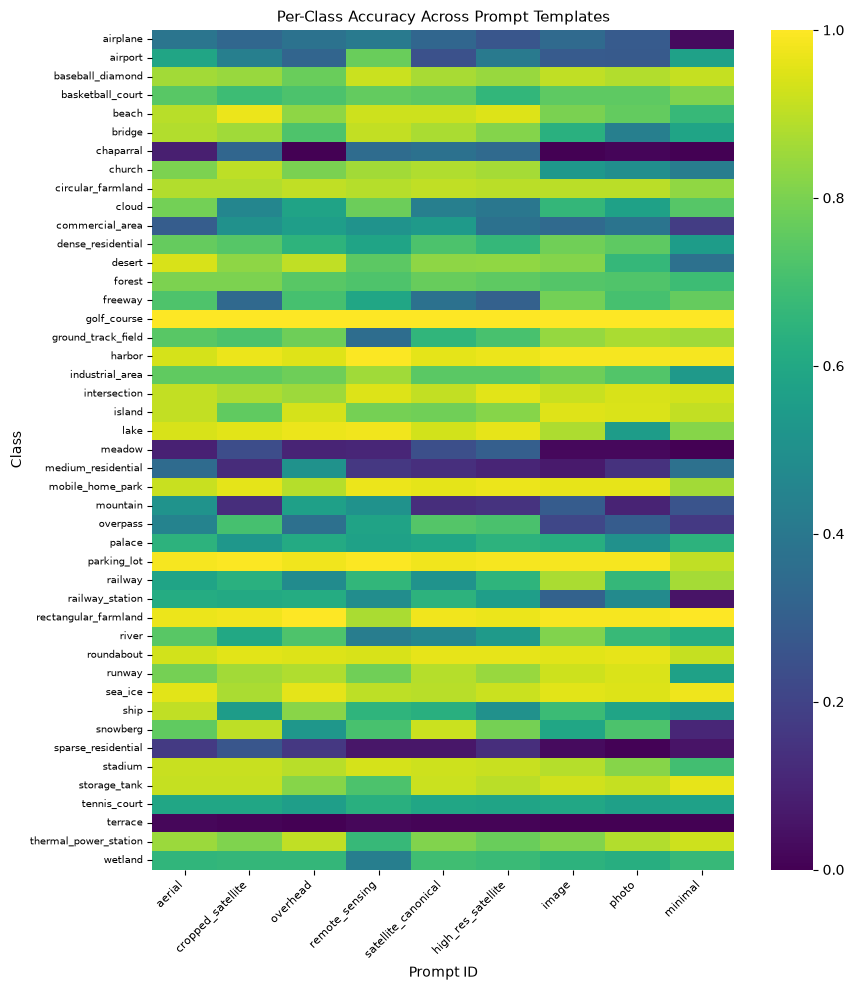

In [35]:
def compute_per_class_prompt_accuracy(prompt_predictions, labels, class_names):
    labels = np.asarray(labels, dtype=int)
    rows = []

    for prompt_id, predicted_labels in prompt_predictions.items():
        predicted_labels = np.asarray(predicted_labels, dtype=int)
        if predicted_labels.shape != labels.shape:
            raise ValueError(
                f"Prediction shape mismatch for prompt '{prompt_id}'."
            )

        for class_id, class_name in enumerate(class_names):
            mask = labels == class_id
            rows.append({
                "prompt_id": prompt_id,
                "class_id": class_id,
                "class_name": class_name,
                "num_samples": int(mask.sum()),
                "accuracy": float(
                    (predicted_labels[mask] == labels[mask]).mean()
                ) if mask.any() else np.nan,
            })

    return pd.DataFrame(rows)


df_per_class_prompt_accuracy = compute_per_class_prompt_accuracy(
    prompt_predictions=prompt_predictions,
    labels=prompt_labels,
    class_names=class_names,
)

per_class_prompt_matrix = df_per_class_prompt_accuracy.pivot(
    index="class_name",
    columns="prompt_id",
    values="accuracy",
)

ordered_prompt_ids = df_prompt_results["prompt_id"].tolist()
per_class_prompt_matrix = per_class_prompt_matrix[ordered_prompt_ids]

plt.figure(figsize=(9, 10))

sns.heatmap(
    per_class_prompt_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1,
    annot=False,
    cbar=True,
)

plt.title("Per-Class Accuracy Across Prompt Templates", fontsize=11)
plt.xlabel("Prompt ID")
plt.ylabel("Class")

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=7)

plt.tight_layout()
plt.show()


## 3.6 Template ensembling

This cell evaluates prompt ensembling.

Instead of using one prompt per class, multiple text embeddings are averaged to reduce dependence on a single template.

In [36]:
def evaluate_prompt_ensembles(
    evaluator,
    prompt_bank,
    ensemble_specs,
    image_features,
    labels,
    top_k=5,
):
    rows = []
    predictions = {}

    for ensemble_id, prompt_ids in ensemble_specs.items():
        missing = [
            prompt_id
            for prompt_id in prompt_ids
            if prompt_id not in prompt_bank
        ]
        if missing:
            raise KeyError(
                f"Unknown prompt ids in {ensemble_id}: {missing}"
            )

        templates = [prompt_bank[prompt_id] for prompt_id in prompt_ids]
        text_features = evaluator.build_text_features_from_templates(templates)
        result = evaluator.evaluate_text_features(
            image_features,
            labels,
            text_features,
            top_k=top_k,
        )

        predictions[ensemble_id] = result["predictions"].numpy()
        rows.append({
            "method_type": "prompt_ensemble",
            "method_id": ensemble_id,
            "description": ", ".join(prompt_ids),
            "num_prompts": len(prompt_ids),
            "top1_accuracy": result["top1_accuracy"],
            "recall_at_5": result["recall_at_5"],
        })

    return pd.DataFrame(rows), predictions


top3_prompt_ids = df_prompt_results.head(3)["prompt_id"].tolist()

PROMPT_ENSEMBLES = {
    "domain_ensemble": PROMPT_GROUPS["domain_prompts"],
    "strong_domain_ensemble": PROMPT_GROUPS["strong_domain_prompts"],
    "top3_single_prompt_ensemble": top3_prompt_ids,
}

df_prompt_ensemble_results, ensemble_predictions = evaluate_prompt_ensembles(
    evaluator=prompt_evaluator,
    prompt_bank=PROMPT_BANK,
    ensemble_specs=PROMPT_ENSEMBLES,
    image_features=prompt_image_features,
    labels=prompt_labels,
    top_k=5,
)

single_prompt_comparison = df_prompt_results.copy()
single_prompt_comparison["method_type"] = "single_prompt"
single_prompt_comparison["method_id"] = single_prompt_comparison["prompt_id"]
single_prompt_comparison["description"] = single_prompt_comparison["prompt_template"]
single_prompt_comparison["num_prompts"] = 1

single_prompt_comparison = single_prompt_comparison[
    [
        "method_type",
        "method_id",
        "description",
        "num_prompts",
        "top1_accuracy",
        "recall_at_5",
    ]
]

df_prompt_method_comparison = pd.concat(
    [
        single_prompt_comparison,
        df_prompt_ensemble_results,
    ],
    ignore_index=True,
)

df_prompt_method_comparison = (
    df_prompt_method_comparison
    .sort_values(by="top1_accuracy", ascending=False)
    .reset_index(drop=True)
)

canonical_method_row = df_prompt_method_comparison[
    df_prompt_method_comparison["method_id"] == CANONICAL_PROMPT_ID
].iloc[0]

best_method_row = df_prompt_method_comparison.iloc[0]

BEST_SINGLE_PROMPT_ID = best_prompt_id
BEST_SINGLE_PROMPT_TEMPLATE = best_prompt_template
BEST_OVERALL_PROMPT_METHOD_ID = best_method_row["method_id"]

print("Prompt method comparison")
print("------------------------")
display(df_prompt_method_comparison)

print("Canonical vs best method")
print("------------------------")
print("Canonical method:", canonical_method_row["method_id"])
print(f"Canonical Top-1: {canonical_method_row['top1_accuracy']:.4f}")
print(f"Canonical Recall@5: {canonical_method_row['recall_at_5']:.4f}")

print("\nBest method:", BEST_OVERALL_PROMPT_METHOD_ID)
print("Method type:", best_method_row["method_type"])
print("Description:", best_method_row["description"])
print(f"Best Top-1: {best_method_row['top1_accuracy']:.4f}")
print(f"Best Recall@5: {best_method_row['recall_at_5']:.4f}")

print("\nDelta from canonical")
print("--------------------")
print(f"Top-1 delta: {best_method_row['top1_accuracy'] - canonical_method_row['top1_accuracy']:+.4f}")
print(f"Recall@5 delta: {best_method_row['recall_at_5'] - canonical_method_row['recall_at_5']:+.4f}")


Prompt method comparison
------------------------


,method_type,method_id,description,num_prompts,top1_accuracy,recall_at_5
0,prompt_ensemble,domain_ensemble,"satellite_canonical, remote_sensing, aerial, o...",4,0.714127,0.956667
1,single_prompt,aerial,an aerial image of a {},1,0.710635,0.953810
2,prompt_ensemble,top3_single_prompt_ensemble,"aerial, cropped_satellite, overhead",3,0.710635,0.954444
3,prompt_ensemble,strong_domain_ensemble,"satellite_canonical, remote_sensing, aerial, h...",5,0.700952,0.954921
4,single_prompt,cropped_satellite,a cropped satellite image of a {},1,0.684762,0.945714
5,single_prompt,overhead,an overhead view of a {},1,0.683968,0.937143
6,single_prompt,remote_sensing,a remote sensing image of a {},1,0.678095,0.941905
7,single_prompt,satellite_canonical,a satellite image of a {},1,0.677937,0.946984
8,single_prompt,high_res_satellite,a high resolution satellite image of a {},1,0.670635,0.943492
9,single_prompt,image,an image of a {},1,0.660794,0.918889


Canonical vs best method
------------------------
Canonical method: satellite_canonical
Canonical Top-1: 0.6779
Canonical Recall@5: 0.9470

Best method: domain_ensemble
Method type: prompt_ensemble
Description: satellite_canonical, remote_sensing, aerial, overhead
Best Top-1: 0.7141
Best Recall@5: 0.9567

Delta from canonical
--------------------
Top-1 delta: +0.0362
Recall@5 delta: +0.0097


### Question 1 — Prompt Wording and Zero-Shot Performance

CLIP was evaluated with different prompt templates and prompt ensembles. Compare the canonical prompt with the best prompt method. Based on the prompt comparison table, the per-class prompt heatmap, and the t-SNE error visualization, does changing the prompt significantly improve zero-shot classification?

### Answer:

The canonical prompt, `a satellite image of a {}`, achieved **67.79% Top-1 accuracy** and **94.70% Recall@5**. The best method was the four-template `domain_ensemble` (satellite, remote-sensing, aerial, and overhead), with **71.41% Top-1** and **95.67% Recall@5**. Thus, the gains over the canonical prompt were **+3.62 percentage points in Top-1** and **+0.97 points in Recall@5**. The best single prompt was `an aerial image of a {}`, which reached 71.06% Top-1 and 95.38% Recall@5.

Therefore, prompt wording provides a **modest but meaningful improvement**, not a fundamental solution. The heatmap shows that some classes are quite prompt-sensitive, whereas difficult classes such as `terrace` and `chaparral` remain poor across nearly all templates. In the t-SNE plot, many incorrect samples are mixed with correct samples inside the same neighborhoods. Since changing prompts only changes the text prototypes and leaves the image embeddings and their geometry fixed, these representation-level overlaps remain. Prompt ensembling is useful because it reduces dependence on one wording, but it does not eliminate the main zero-shot errors.


# Part 4 — Contrastive Learning and LoRA Fine-Tuning

In this part, CLIP is adapted to RESISC45 with parameter-efficient fine-tuning.

We build class-based image-text pairs, train LoRA adapters on CLIP, optimize a supervised contrastive objective, and compare the fine-tuned model with the base zero-shot model on the full test split.

## 4.1 Check the validation split

This cell verifies that the train, validation, and full test splits are available before fine-tuning.

The validation split is used for monitoring loss during training, and the full test split is reserved for final evaluation.

In [37]:
if validation_ds is None:
    raise ValueError("Validation split is missing. Check Part 0.8 and Part 0.9.")

required_objects = [
    "train_ds",
    "validation_ds",
    "test_full_ds",
    "train_loader",
    "validation_loader",
    "test_full_loader",
    "zero_shot_results",
    "base_full_test_results",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(f"Missing required objects before Part 4: {missing_objects}")

split_check_df = pd.DataFrame([
    {
        "split": "train",
        "num_images": len(train_ds),
        "loader_batches": len(train_loader),
    },
    {
        "split": "validation",
        "num_images": len(validation_ds),
        "loader_batches": len(validation_loader),
    },
    {
        "split": "test",
        "num_images": len(test_full_ds),
        "loader_batches": len(test_full_loader),
    },
])

display(split_check_df)

print("Base CLIP results from Part 1")
print("-----------------------------")
print("Prompt templates:", base_full_test_results["prompt_templates"])
print(f"Top-1 accuracy: {base_full_test_results['top1_accuracy']:.4f}")
print(f"Recall@5:       {base_full_test_results['recall_at_5']:.4f}")

,split,num_images,loader_batches
0,train,18900,1182
1,validation,6300,394
2,test,6300,394


Base CLIP results from Part 1
-----------------------------
Prompt templates: ['a satellite image of a airplane', 'a satellite image of a airport', 'a satellite image of a baseball diamond', 'a satellite image of a basketball court', 'a satellite image of a beach', 'a satellite image of a bridge', 'a satellite image of a chaparral', 'a satellite image of a church', 'a satellite image of a circular farmland', 'a satellite image of a cloud', 'a satellite image of a commercial area', 'a satellite image of a dense residential', 'a satellite image of a desert', 'a satellite image of a forest', 'a satellite image of a freeway', 'a satellite image of a golf course', 'a satellite image of a ground track field', 'a satellite image of a harbor', 'a satellite image of a industrial area', 'a satellite image of a intersection', 'a satellite image of a island', 'a satellite image of a lake', 'a satellite image of a meadow', 'a satellite image of a medium residential', 'a satellite image of a mobile 

## 4.2 Fine-tuning configuration

This cell defines the main fine-tuning settings.

LoRA updates a low-rank correction for a frozen weight matrix,
$W' = W + \Delta W$, with $\Delta W = BA$ and rank $r \ll \min(d,k)$.
This reduces the number of trainable parameters and makes CLIP fine-tuning more memory-efficient.

The cell sets the LoRA hyperparameters, optimizer settings, batch sizes, and mixed-precision options.

In [50]:
PART4_DIR = OUTPUT_DIR / "part4_lora_finetuning"
PART4_DIR.mkdir(parents=True, exist_ok=True)

MERGED_MODEL_DIR = PART4_DIR / "clip_resisc45_lora_merged"

FT_MAX_TEXT_LENGTH = 77

# Conservative LoRA configuration for CLIP ViT-L/14 on a Colab T4.
LORA_RANK = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05

LORA_TARGET_MODULES = [
    "q_proj",
    "k_proj",
    "v_proj",
    "out_proj",
]

# Effective training batch size = 8 * 4 = 32.
FT_TRAIN_BATCH_SIZE = 8
FT_VAL_BATCH_SIZE = 16
FT_EVAL_BATCH_SIZE = 16

FT_NUM_EPOCHS =1
FT_LEARNING_RATE = 1e-4
FT_WEIGHT_DECAY = 1e-2
FT_WARMUP_RATIO = 0.10
FT_GRADIENT_ACCUMULATION_STEPS = 4
FT_MAX_GRAD_NORM = 1.0

USE_AMP = torch.cuda.is_available()
ENABLE_GRADIENT_CHECKPOINTING = True

USE_TRAIN_SUBSET_FOR_DEBUG = False
TRAIN_IMAGES_PER_CLASS_DEBUG = 50

ft_config_df = pd.DataFrame([
    {"name": "CLIP model", "value": CLIP_MODEL_ID},
    {"name": "LoRA rank", "value": LORA_RANK},
    {"name": "LoRA alpha", "value": LORA_ALPHA},
    {"name": "LoRA dropout", "value": LORA_DROPOUT},
    {"name": "train batch size", "value": FT_TRAIN_BATCH_SIZE},
    {"name": "validation batch size", "value": FT_VAL_BATCH_SIZE},
    {"name": "eval batch size", "value": FT_EVAL_BATCH_SIZE},
    {"name": "gradient accumulation steps", "value": FT_GRADIENT_ACCUMULATION_STEPS},
    {"name": "effective train batch size", "value": FT_TRAIN_BATCH_SIZE * FT_GRADIENT_ACCUMULATION_STEPS},
    {"name": "epochs", "value": FT_NUM_EPOCHS},
    {"name": "learning rate", "value": FT_LEARNING_RATE},
    {"name": "mixed precision", "value": USE_AMP},
    {"name": "gradient checkpointing", "value": ENABLE_GRADIENT_CHECKPOINTING},
])

display(ft_config_df)


,name,value
0,CLIP model,openai/clip-vit-large-patch14
1,LoRA rank,8
2,LoRA alpha,16
3,LoRA dropout,0.05
4,train batch size,8
5,validation batch size,16
6,eval batch size,16
7,gradient accumulation steps,4
8,effective train batch size,32
9,epochs,1


## 4.3 Select prompt templates for fine-tuning

RESISC45 provides class labels but not natural captions, so each training image is paired with a class-based prompt.

This cell selects the prompt templates used for fine-tuning and keeps the canonical prompt for fair final evaluation.

In [39]:
def unique_list(items):
    seen = set()
    output = []

    for item in items:
        if item not in seen:
            output.append(item)
            seen.add(item)

    return output


def resolve_finetuning_prompt_templates():
    templates = []

    # Reuse the strongest single prompts found in Part 3, if available.
    if "df_prompt_results" in globals() and "PROMPT_BANK" in globals():
        top_prompt_ids = df_prompt_results.head(3)["prompt_id"].tolist()

        for prompt_id in top_prompt_ids:
            templates.append(PROMPT_BANK[prompt_id])

    # Always include domain-specific remote-sensing prompts.
    if "PROMPT_BANK" in globals():
        fallback_prompt_ids = [
            "satellite_canonical",
            "remote_sensing",
            "aerial",
            "overhead",
        ]

        for prompt_id in fallback_prompt_ids:
            if prompt_id in PROMPT_BANK:
                templates.append(PROMPT_BANK[prompt_id])

    if len(templates) == 0:
        templates = [
            "a satellite image of a {}",
            "a remote sensing image of a {}",
            "an aerial image of a {}",
            "an overhead view of a {}",
        ]

    return unique_list(templates)


FINE_TUNE_PROMPT_TEMPLATES = resolve_finetuning_prompt_templates()

# Use the same prompt as Part 1 for fair base-vs-fine-tuned comparison.
EVAL_PROMPT_TEMPLATE = CANONICAL_PROMPT_TEMPLATE
EVAL_PROMPT_TEMPLATES = [EVAL_PROMPT_TEMPLATE]

prompt_config_df = pd.DataFrame([
    {
        "usage": "fine_tuning",
        "template": template,
    }
    for template in FINE_TUNE_PROMPT_TEMPLATES
] + [
    {
        "usage": "final_evaluation",
        "template": EVAL_PROMPT_TEMPLATE,
    }
])

display(prompt_config_df)

print("Final evaluation uses the same prompt as Part 1:")
print(EVAL_PROMPT_TEMPLATE)

,usage,template
0,fine_tuning,an aerial image of a {}
1,fine_tuning,a cropped satellite image of a {}
2,fine_tuning,an overhead view of a {}
3,fine_tuning,a satellite image of a {}
4,fine_tuning,a remote sensing image of a {}
5,final_evaluation,a satellite image of a {}


Final evaluation uses the same prompt as Part 1:
a satellite image of a {}


## 4.4 Build contrastive datasets

This cell builds image-text pairs for contrastive training.

For each image, the text is generated from its class label. During training, prompts are sampled from a prompt pool to increase variation, while validation uses a fixed prompt for a more stable loss estimate.

In [40]:
class RESISC45ContrastiveDataset(Dataset):
    """Pairs each RESISC45 image with a class-derived caption."""

    def __init__(
        self,
        hf_dataset,
        id2label,
        class_names_clean,
        prompt_templates,
        training=False,
        seed=42,
    ):
        if len(prompt_templates) == 0:
            raise ValueError("prompt_templates cannot be empty.")

        self.hf_dataset = hf_dataset
        self.id2label = dict(id2label)
        self.class_names_clean = list(class_names_clean)
        self.prompt_templates = list(prompt_templates)
        self.training = bool(training)
        self.rng = random.Random(seed)

    def __len__(self):
        return len(self.hf_dataset)

    def build_caption(self, label):
        label = int(label)
        template = (
            self.rng.choice(self.prompt_templates)
            if self.training
            else self.prompt_templates[0]
        )
        return template.format(self.class_names_clean[label])

    def __getitem__(self, index):
        sample = self.hf_dataset[int(index)]
        image = sample["image"]
        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))
        image = image.convert("RGB")

        label = int(sample["label"])
        return {
            "image": image,
            "caption": self.build_caption(label),
            "label": label,
            "class_name": self.id2label[label],
            "image_id": str(sample.get("image_id", index)),
        }


def clip_contrastive_collate_fn(batch):
    if len(batch) == 0:
        raise ValueError("Cannot collate an empty batch.")

    images = [sample["image"] for sample in batch]
    captions = [sample["caption"] for sample in batch]
    encoded = processor(
        text=captions,
        images=images,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=FT_MAX_TEXT_LENGTH,
    )

    return {
        "input_ids": encoded["input_ids"],
        "attention_mask": encoded["attention_mask"],
        "pixel_values": encoded["pixel_values"],
        "labels": torch.tensor(
            [sample["label"] for sample in batch],
            dtype=torch.long,
        ),
        "captions": captions,
        "class_names": [sample["class_name"] for sample in batch],
        "image_ids": [sample["image_id"] for sample in batch],
    }


## 4.5 Create training and validation dataloaders

This cell creates the dataloaders used for LoRA fine-tuning.

The training loader uses the train split, and the validation loader uses the validation split. An optional balanced subset can be used for debugging.

In [41]:
if USE_TRAIN_SUBSET_FOR_DEBUG:
    debug_train_indices = balanced_subset_indices(
        train_ds,
        n_per_class=TRAIN_IMAGES_PER_CLASS_DEBUG,
        seed=RANDOM_SEED,
    )

    train_ft_hf_ds = train_ds.select(debug_train_indices)
else:
    train_ft_hf_ds = train_ds


train_contrastive_dataset = RESISC45ContrastiveDataset(
    hf_dataset=train_ft_hf_ds,
    id2label=id2label,
    class_names_clean=class_names_clean,
    prompt_templates=FINE_TUNE_PROMPT_TEMPLATES,
    training=True,
    seed=RANDOM_SEED,
)

validation_contrastive_dataset = RESISC45ContrastiveDataset(
    hf_dataset=validation_ds,
    id2label=id2label,
    class_names_clean=class_names_clean,
    prompt_templates=EVAL_PROMPT_TEMPLATES,
    training=False,
    seed=RANDOM_SEED,
)

train_contrastive_loader = DataLoader(
    train_contrastive_dataset,
    batch_size=FT_TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=clip_contrastive_collate_fn,
    pin_memory=torch.cuda.is_available(),
)

validation_contrastive_loader = DataLoader(
    validation_contrastive_dataset,
    batch_size=FT_VAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=clip_contrastive_collate_fn,
    pin_memory=torch.cuda.is_available(),
)

sample_ft_batch = next(iter(train_contrastive_loader))

batch_check_df = pd.DataFrame([
    {
        "field": "input_ids",
        "shape": tuple(sample_ft_batch["input_ids"].shape),
    },
    {
        "field": "attention_mask",
        "shape": tuple(sample_ft_batch["attention_mask"].shape),
    },
    {
        "field": "pixel_values",
        "shape": tuple(sample_ft_batch["pixel_values"].shape),
    },
    {
        "field": "labels",
        "shape": tuple(sample_ft_batch["labels"].shape),
    },
])

loader_check_df = pd.DataFrame([
    {
        "loader": "train_contrastive_loader",
        "dataset_size": len(train_contrastive_dataset),
        "batch_size": FT_TRAIN_BATCH_SIZE,
        "num_batches": len(train_contrastive_loader),
    },
    {
        "loader": "validation_contrastive_loader",
        "dataset_size": len(validation_contrastive_dataset),
        "batch_size": FT_VAL_BATCH_SIZE,
        "num_batches": len(validation_contrastive_loader),
    },
])

display(loader_check_df)
display(batch_check_df)

print("Example training caption:")
print(sample_ft_batch["captions"][0])

,loader,dataset_size,batch_size,num_batches
0,train_contrastive_loader,18900,8,2363
1,validation_contrastive_loader,6300,16,394


,field,shape
0,input_ids,"(8, 10)"
1,attention_mask,"(8, 10)"
2,pixel_values,"(8, 3, 224, 224)"
3,labels,"(8,)"


Example training caption:
an aerial image of a intersection


## 4.6 CLIP feature helpers

This cell defines helper functions for manually computing CLIP text and image embeddings.

The helpers keep the feature extraction path compatible with both the original CLIP model and the LoRA-wrapped PEFT model.

In [42]:
def unwrap_clip_model(clip_model):
    if hasattr(clip_model, "get_base_model"):
        return clip_model.get_base_model()
    if hasattr(clip_model, "base_model") and hasattr(
        clip_model.base_model,
        "model",
    ):
        return clip_model.base_model.model
    return clip_model


def move_batch_to_device(batch, device):
    return {
        key: value.to(device, non_blocking=True)
        if torch.is_tensor(value)
        else value
        for key, value in batch.items()
    }


def encode_clip_text_features_from_inputs(clip_model, input_ids, attention_mask):
    base_model = unwrap_clip_model(clip_model)
    features = base_model.get_text_features(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
    return F.normalize(features, dim=-1)


def encode_clip_image_features_from_inputs(clip_model, pixel_values):
    base_model = unwrap_clip_model(clip_model)
    features = base_model.get_image_features(pixel_values=pixel_values)
    return F.normalize(features, dim=-1)


def get_clip_logit_scale(clip_model):
    base_model = unwrap_clip_model(clip_model)
    return base_model.logit_scale.exp().clamp(max=100.0)


## 4.7 Supervised CLIP contrastive loss

This cell defines the supervised contrastive loss used for fine-tuning.

For normalized image features $v_i$ and text features $t_j$, the similarity is
$s_{ij} = \exp(\tau)\, v_i^\top t_j$.

Unlike standard CLIP loss, this implementation treats all image-text pairs with the same class label as positives inside the batch. The final objective averages the image-to-text and text-to-image supervised contrastive losses.

In [43]:
def supervised_clip_contrastive_loss(
    clip_model,
    batch,
):
    text_features = encode_clip_text_features_from_inputs(
        clip_model,
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
    )
    image_features = encode_clip_image_features_from_inputs(
        clip_model,
        pixel_values=batch["pixel_values"],
    )

    logits_per_image = (
        get_clip_logit_scale(clip_model)
        * image_features
        @ text_features.T
    )
    logits_per_text = logits_per_image.T

    labels = batch["labels"].view(-1)
    positive_mask = labels[:, None].eq(labels[None, :]).float()
    positive_count = positive_mask.sum(dim=1).clamp_min(1.0)

    image_log_prob = F.log_softmax(logits_per_image, dim=1)
    text_log_prob = F.log_softmax(logits_per_text, dim=1)

    image_to_text_loss = -(
        (positive_mask * image_log_prob).sum(dim=1) / positive_count
    ).mean()
    text_to_image_loss = -(
        (positive_mask.T * text_log_prob).sum(dim=1) / positive_count
    ).mean()

    return 0.5 * (image_to_text_loss + text_to_image_loss)


## 4.8 Build the LoRA CLIP model

This cell loads a fresh CLIP model and inserts LoRA adapters into the attention projection layers.

Most original CLIP weights remain frozen, while only the low-rank adapter parameters are trained. The cell also reports the number of trainable parameters.

In [47]:
def prepare_peft_for_lora():
    try:
        from peft import LoraConfig as PeftLoraConfig
        from peft import get_peft_model as peft_get_peft_model
    except ImportError as error:
        raise ImportError(
            "PEFT is required. Re-run the package-installation cell."
        ) from error

    return PeftLoraConfig, peft_get_peft_model


# def build_lora_clip_model():
#     PeftLoraConfig, peft_get_peft_model = prepare_peft_for_lora()

#     clip_model = CLIPModel.from_pretrained(
#         CLIP_MODEL_ID,
#         cache_dir=str(CACHE_DIR),
#     )

#     if ENABLE_GRADIENT_CHECKPOINTING:
#         clip_model.gradient_checkpointing_enable()

#     lora_config = PeftLoraConfig(
#         r=LORA_RANK,
#         lora_alpha=LORA_ALPHA,
#         lora_dropout=LORA_DROPOUT,
#         target_modules=LORA_TARGET_MODULES,
#         bias="none",
#     )
#     return peft_get_peft_model(clip_model, lora_config)

def build_lora_clip_model():
    PeftLoraConfig, peft_get_peft_model = prepare_peft_for_lora()

    clip_model = CLIPModel.from_pretrained(
        CLIP_MODEL_ID,
        cache_dir=str(CACHE_DIR),
    )

    lora_config = PeftLoraConfig(
        r=LORA_RANK,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=LORA_TARGET_MODULES,
        bias="none",
    )

    # ابتدا LoRA را اضافه می‌کنیم؛ در این لحظه checkpointing غیرفعال است.
    lora_model = peft_get_peft_model(
        clip_model,
        lora_config,
    )

    # سپس checkpointing را با حالت non-reentrant فعال می‌کنیم.
    if ENABLE_GRADIENT_CHECKPOINTING:
        clip_model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={
                "use_reentrant": False
            }
        )

    return lora_model

def count_trainable_parameters(model_to_count):
    total_params = sum(
        parameter.numel()
        for parameter in model_to_count.parameters()
    )
    trainable_params = sum(
        parameter.numel()
        for parameter in model_to_count.parameters()
        if parameter.requires_grad
    )

    return {
        "total_params": total_params,
        "trainable_params": trainable_params,
        "trainable_percent": (
            100.0 * trainable_params / total_params
            if total_params
            else 0.0
        ),
    }


if "model" in globals():
    model.to("cpu")
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


lora_model = build_lora_clip_model()
lora_model = lora_model.to(DEVICE)

param_summary = count_trainable_parameters(lora_model)

param_summary_df = pd.DataFrame([
    {
        "metric": "total_parameters",
        "value": param_summary["total_params"],
    },
    {
        "metric": "trainable_parameters",
        "value": param_summary["trainable_params"],
    },
    {
        "metric": "trainable_percent",
        "value": param_summary["trainable_percent"],
    },
])

display(param_summary_df)

try:
    lora_model.print_trainable_parameters()
except Exception as error:
    print("Could not print PEFT parameter summary:", repr(error))


,metric,value
0,total_parameters,4.297792e+08
1,trainable_parameters,2.162688e+06
2,trainable_percent,5.032091e-01


trainable params: 2,162,688 || all params: 429,779,201 || trainable%: 0.5032


## 4.9 Training engine

This class manages the LoRA fine-tuning loop.

It handles optimization, gradient accumulation, mixed precision, validation loss computation, and training-history logging across epochs.

In [48]:
class CLIPLoRAFineTuner:
    """Training engine for supervised multi-positive CLIP LoRA adaptation."""

    def __init__(
        self,
        model,
        train_loader,
        validation_loader,
        device,
        learning_rate,
        weight_decay,
        num_epochs,
        warmup_ratio,
        gradient_accumulation_steps,
        max_grad_norm,
        use_amp,
    ):
        self.model = model
        self.train_loader = train_loader
        self.validation_loader = validation_loader
        self.device = torch.device(device)
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.num_epochs = num_epochs
        self.warmup_ratio = warmup_ratio
        self.gradient_accumulation_steps = gradient_accumulation_steps
        self.max_grad_norm = max_grad_norm
        self.use_amp = bool(use_amp and self.device.type == "cuda")
        self.history = []

        self.scaler = torch.cuda.amp.GradScaler(enabled=self.use_amp)
        self.setup_optimizer_and_scheduler()

    def setup_optimizer_and_scheduler(self):
        trainable_parameters = [
            parameter
            for parameter in self.model.parameters()
            if parameter.requires_grad
        ]
        self.optimizer = torch.optim.AdamW(
            trainable_parameters,
            lr=self.learning_rate,
            weight_decay=self.weight_decay,
        )

        updates_per_epoch = math.ceil(
            len(self.train_loader) / self.gradient_accumulation_steps
        )
        total_steps = max(1, updates_per_epoch * self.num_epochs)
        warmup_steps = int(total_steps * self.warmup_ratio)

        self.scheduler = get_cosine_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps,
        )

    def train_one_epoch(self, epoch_index):
        self.model.train()
        self.optimizer.zero_grad(set_to_none=True)
        total_loss = 0.0
        total_samples = 0

        progress = tqdm(
            self.train_loader,
            desc=f"Train epoch {epoch_index + 1}/{self.num_epochs}",
        )

        for step, raw_batch in enumerate(progress):
            batch = move_batch_to_device(raw_batch, self.device)
            batch_size = batch["labels"].shape[0]

            with torch.autocast(
                device_type=self.device.type,
                dtype=torch.float16,
                enabled=self.use_amp,
            ):
                raw_loss = supervised_clip_contrastive_loss(
                    self.model,
                    batch,
                )
                loss = raw_loss / self.gradient_accumulation_steps

            self.scaler.scale(loss).backward()

            should_step = (
                (step + 1) % self.gradient_accumulation_steps == 0
                or (step + 1) == len(self.train_loader)
            )

            if should_step:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(
                    [
                        parameter
                        for parameter in self.model.parameters()
                        if parameter.requires_grad
                    ],
                    self.max_grad_norm,
                )
                self.scaler.step(self.optimizer)
                self.scaler.update()
                self.scheduler.step()
                self.optimizer.zero_grad(set_to_none=True)

            total_loss += float(raw_loss.detach().cpu()) * batch_size
            total_samples += batch_size
            progress.set_postfix(loss=f"{raw_loss.item():.4f}")

        return total_loss / max(total_samples, 1)

    @torch.no_grad()
    def validate_loss(self):
        self.model.eval()
        total_loss = 0.0
        total_samples = 0

        for raw_batch in tqdm(
            self.validation_loader,
            desc="Validation",
            leave=False,
        ):
            batch = move_batch_to_device(raw_batch, self.device)
            batch_size = batch["labels"].shape[0]

            with torch.autocast(
                device_type=self.device.type,
                dtype=torch.float16,
                enabled=self.use_amp,
            ):
                loss = supervised_clip_contrastive_loss(
                    self.model,
                    batch,
                )

            total_loss += float(loss.detach().cpu()) * batch_size
            total_samples += batch_size

        return total_loss / max(total_samples, 1)

    def fit(self):
        for epoch_index in range(self.num_epochs):
            start_time = time.perf_counter()
            train_loss = self.train_one_epoch(epoch_index)
            validation_loss = self.validate_loss()
            epoch_time = time.perf_counter() - start_time
            current_lr = self.optimizer.param_groups[0]["lr"]

            row = {
                "epoch": epoch_index + 1,
                "train_loss": train_loss,
                "val_loss": validation_loss,
                "learning_rate": current_lr,
                "epoch_time_seconds": epoch_time,
            }
            self.history.append(row)

            print(
                f"Epoch {epoch_index + 1}/{self.num_epochs} | "
                f"train={train_loss:.4f} | "
                f"val={validation_loss:.4f} | "
                f"lr={current_lr:.2e} | "
                f"time={epoch_time:.1f}s"
            )

        return pd.DataFrame(self.history)


## 4.10 Run LoRA fine-tuning

This cell runs LoRA fine-tuning on the training split and evaluates the validation loss after each epoch.

The output is a training-history table that summarizes the optimization process.

In [51]:
fine_tuner = CLIPLoRAFineTuner(
    model=lora_model,
    train_loader=train_contrastive_loader,
    validation_loader=validation_contrastive_loader,
    device=DEVICE,
    learning_rate=FT_LEARNING_RATE,
    weight_decay=FT_WEIGHT_DECAY,
    num_epochs=FT_NUM_EPOCHS,
    warmup_ratio=FT_WARMUP_RATIO,
    gradient_accumulation_steps=FT_GRADIENT_ACCUMULATION_STEPS,
    max_grad_norm=FT_MAX_GRAD_NORM,
    use_amp=USE_AMP,
)

df_training_history = fine_tuner.fit()

display(
    df_training_history.round({
        "train_loss": 4,
        "val_loss": 4,
        "learning_rate": 8,
        "epoch_time_seconds": 2,
    })
)

C:\Users\psp\AppData\Local\Temp\ipykernel_3532\1328649759.py:31: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=self.use_amp)
Train epoch 1/1:   0%|          | 0/2363 [00:00<?, ?it/s]

Train epoch 1/1:  20%|█▉        | 461/2363 [1:31:23<6:17:05, 11.90s/it, loss=0.0171]


KeyboardInterrupt: 

## 4.11 Merge LoRA adapters into CLIP

After training, the LoRA adapters are merged into the base CLIP weights.

The merged model is easier to save, reload, and use in the later retrieval and generation experiments.

In [ ]:
# from pathlib import Path

# PARTIAL_ADAPTER_PATH = Path("./clip_lora_partial")

# lora_model.save_pretrained(
#     PARTIAL_ADAPTER_PATH,
#     safe_serialization=True,
# )

# print("Saved:", PARTIAL_ADAPTER_PATH.resolve())

Saved: I:\دانشگاه\ترم 8\Deep learning\HW\HW5\clip_lora_partial


In [53]:
lora_model.eval()

merged_lora_model = lora_model.merge_and_unload()
merged_lora_model = merged_lora_model.to(DEVICE)
merged_lora_model.eval()

merged_lora_model.save_pretrained(MERGED_MODEL_DIR)
processor.save_pretrained(MERGED_MODEL_DIR)

print("Merged fine-tuned CLIP model saved to:")
print(MERGED_MODEL_DIR)

# The PEFT wrapper is no longer needed after merging.
if "fine_tuner" in globals():
    del fine_tuner

if "lora_model" in globals():
    del lora_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Merged fine-tuned CLIP model saved to:
\content\resisc45_clip_project\outputs\part4_lora_finetuning\clip_resisc45_lora_merged


## 4.12 Evaluate the fine-tuned model on the full test split

This cell evaluates the fine-tuned CLIP model on the full RESISC45 test split.

The same evaluation prompt used in Part 1 is kept here so that the comparison between base CLIP and fine-tuned CLIP remains fair.

In [54]:
@torch.no_grad()
def encode_prompt_templates_for_model(
    clip_model,
    processor,
    class_names_clean,
    prompt_templates,
    device,
    batch_size=64,
):
    if isinstance(prompt_templates, str):
        prompt_templates = [prompt_templates]
    if len(prompt_templates) == 0:
        raise ValueError("At least one prompt template is required.")

    clip_model.eval()
    per_template = []

    for template in prompt_templates:
        prompts = [
            template.format(class_name)
            for class_name in class_names_clean
        ]
        feature_batches = []

        for start in range(0, len(prompts), batch_size):
            inputs = processor(
                text=prompts[start:start + batch_size],
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=77,
            )
            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }
            features = clip_model.get_text_features(
                input_ids=inputs["input_ids"],
                attention_mask=inputs.get("attention_mask"),
            )
            feature_batches.append(F.normalize(features, dim=-1))

        per_template.append(torch.cat(feature_batches, dim=0))

    class_features = torch.stack(per_template, dim=0).mean(dim=0)
    return F.normalize(class_features, dim=-1)


@torch.no_grad()
def evaluate_clip_zero_shot_on_loader(
    clip_model,
    processor,
    dataloader,
    class_names,
    class_names_clean,
    prompt_templates,
    device,
    top_k=5,
):
    clip_model.eval()
    start_time = time.perf_counter()

    text_features = encode_prompt_templates_for_model(
        clip_model,
        processor,
        class_names_clean,
        prompt_templates,
        device,
    )
    logit_scale = clip_model.logit_scale.exp().clamp(max=100.0)

    storage = defaultdict(list)
    image_ids = []

    for batch in tqdm(dataloader, desc="Fine-tuned zero-shot evaluation"):
        inputs = processor(
            images=batch["images"],
            return_tensors="pt",
        )
        pixel_values = inputs["pixel_values"].to(device)
        image_features = F.normalize(
            clip_model.get_image_features(pixel_values=pixel_values),
            dim=-1,
        )

        logits = logit_scale * image_features @ text_features.T
        probabilities = logits.softmax(dim=-1)
        predictions = probabilities.argmax(dim=-1)
        effective_k = min(top_k, len(class_names))
        top_probabilities, top_indices = probabilities.topk(
            effective_k,
            dim=-1,
        )

        storage["image_features"].append(image_features.cpu())
        storage["logits"].append(logits.cpu())
        storage["probabilities"].append(probabilities.cpu())
        storage["predictions"].append(predictions.cpu())
        storage["top_indices"].append(top_indices.cpu())
        storage["top_probabilities"].append(top_probabilities.cpu())
        storage["labels"].append(batch["labels"].cpu())
        image_ids.extend(batch["image_ids"])

    results = {
        key: torch.cat(value, dim=0)
        for key, value in storage.items()
    }
    results["image_ids"] = image_ids
    results["prompt_templates"] = list(prompt_templates)
    results["top1_accuracy"] = compute_top1_accuracy(
        results["labels"].numpy(),
        results["predictions"].numpy(),
    )
    results["recall_at_5"] = compute_recall_at_k(
        results["labels"].numpy(),
        results["top_indices"].numpy(),
        k=min(5, effective_k),
    )
    results["elapsed_time"] = time.perf_counter() - start_time
    return results


In [55]:
# Use the same prompt as Part 1 for a fair comparison with base CLIP.
# This is important because base_full_test_results was computed in Part 1
# with CANONICAL_PROMPT_TEMPLATE.

if "EVAL_PROMPT_TEMPLATES" not in globals():
    EVAL_PROMPT_TEMPLATE = CANONICAL_PROMPT_TEMPLATE
    EVAL_PROMPT_TEMPLATES = [EVAL_PROMPT_TEMPLATE]

if EVAL_PROMPT_TEMPLATES != [CANONICAL_PROMPT_TEMPLATE]:
    print("Warning: Evaluation prompt is not the same as Part 1.")
    print("Current evaluation prompts:", EVAL_PROMPT_TEMPLATES)
    print("Resetting to canonical prompt for fair comparison.")

    EVAL_PROMPT_TEMPLATE = CANONICAL_PROMPT_TEMPLATE
    EVAL_PROMPT_TEMPLATES = [EVAL_PROMPT_TEMPLATE]

fine_tuned_full_test_results = evaluate_clip_zero_shot_on_loader(
    clip_model=merged_lora_model,
    processor=processor,
    dataloader=test_full_loader,
    class_names=class_names,
    class_names_clean=class_names_clean,
    prompt_templates=EVAL_PROMPT_TEMPLATES,
    device=DEVICE,
    top_k=5,
)

print("Fine-tuned CLIP full test results")
print("---------------------------------")
print("Evaluation split: full test")
print("Prompt template:", EVAL_PROMPT_TEMPLATES[0])
print(f"Top-1 accuracy: {fine_tuned_full_test_results['top1_accuracy']:.4f}")
print(f"Recall@5:       {fine_tuned_full_test_results['recall_at_5']:.4f}")
print(f"Images:         {len(fine_tuned_full_test_results['labels'])}")
print(f"Time:           {fine_tuned_full_test_results['elapsed_time']:.2f} seconds")

Fine-tuned zero-shot evaluation: 100%|██████████| 394/394 [11:22<00:00,  1.73s/it]

Fine-tuned CLIP full test results
---------------------------------
Evaluation split: full test
Prompt template: a satellite image of a {}
Top-1 accuracy: 0.8870
Recall@5:       0.9962
Images:         6300
Time:           682.78 seconds


## 4.13 Build prediction tables

This cell builds prediction tables for the base model and the fine-tuned model.

These tables make it easier to compare overall performance and inspect prediction differences at the image level.

In [56]:
def to_numpy_array(value):
    if torch.is_tensor(value):
        return value.detach().cpu().numpy()

    return np.asarray(value)


def build_full_test_prediction_dataframe(results, class_names, method_name):
    labels = to_numpy_array(results["labels"]).astype(int)
    predictions = to_numpy_array(results["predictions"]).astype(int)
    top_indices = to_numpy_array(results["top_indices"]).astype(int)

    rows = []

    for row_index in range(len(labels)):
        true_label = int(labels[row_index])
        pred_label = int(predictions[row_index])

        row = {
            "row_index": row_index,
            "image_id": results["image_ids"][row_index],
            "method": method_name,
            "true_label": true_label,
            "true_class": class_names[true_label],
            "pred_label": pred_label,
            "pred_class": class_names[pred_label],
            "correct": bool(true_label == pred_label),
        }

        for rank in range(top_indices.shape[1]):
            class_index = int(top_indices[row_index, rank])
            row[f"top{rank + 1}_class"] = class_names[class_index]

        rows.append(row)

    return pd.DataFrame(rows)


df_base_full_test_predictions = build_full_test_prediction_dataframe(
    results=base_full_test_results,
    class_names=class_names,
    method_name="base_clip",
)

df_finetuned_full_test_predictions = build_full_test_prediction_dataframe(
    results=fine_tuned_full_test_results,
    class_names=class_names,
    method_name="lora_finetuned_clip",
)

overall_comparison = pd.DataFrame([
    {
        "method": "base_clip",
        "top1_accuracy": base_full_test_results["top1_accuracy"],
        "recall_at_5": base_full_test_results["recall_at_5"],
        "num_test_images": len(to_numpy_array(base_full_test_results["labels"])),
        "prompt_template": base_full_test_results["prompt_templates"][0],
    },
    {
        "method": "lora_finetuned_clip",
        "top1_accuracy": fine_tuned_full_test_results["top1_accuracy"],
        "recall_at_5": fine_tuned_full_test_results["recall_at_5"],
        "num_test_images": len(to_numpy_array(fine_tuned_full_test_results["labels"])),
        "prompt_template": fine_tuned_full_test_results["prompt_templates"][0],
    },
])

overall_delta = {
    "top1_accuracy_delta": (
        fine_tuned_full_test_results["top1_accuracy"]
        - base_full_test_results["top1_accuracy"]
    ),
    "recall_at_5_delta": (
        fine_tuned_full_test_results["recall_at_5"]
        - base_full_test_results["recall_at_5"]
    ),
}

display(overall_comparison)

print("Overall improvement")
print("-------------------")
print(f"Top-1 accuracy delta: {overall_delta['top1_accuracy_delta']:+.4f}")
print(f"Recall@5 delta:       {overall_delta['recall_at_5_delta']:+.4f}")

,method,top1_accuracy,recall_at_5,num_test_images,prompt_template
0,base_clip,0.677937,0.946984,6300,a satellite image of a airplane
1,lora_finetuned_clip,0.886984,0.996190,6300,a satellite image of a {}


Overall improvement
-------------------
Top-1 accuracy delta: +0.2090
Recall@5 delta:       +0.0492


## 4.14 Compare per-class accuracy before and after fine-tuning

This cell compares per-class accuracy before and after LoRA fine-tuning.

It highlights which classes benefit from adaptation and which classes remain difficult.

In [57]:
df_base_per_class_accuracy = compute_per_class_accuracy(
    prediction_df=df_base_full_test_predictions,
    class_names=class_names,
)

df_finetuned_per_class_accuracy = compute_per_class_accuracy(
    prediction_df=df_finetuned_full_test_predictions,
    class_names=class_names,
)

df_per_class_finetune_comparison = df_base_per_class_accuracy.merge(
    df_finetuned_per_class_accuracy,
    on=["class_id", "class_name", "total"],
    suffixes=("_base", "_finetuned"),
)

df_per_class_finetune_comparison["accuracy_delta"] = (
    df_per_class_finetune_comparison["accuracy_finetuned"]
    - df_per_class_finetune_comparison["accuracy_base"]
)

df_per_class_finetune_comparison = (
    df_per_class_finetune_comparison
    .sort_values(by="accuracy_delta", ascending=False)
    .reset_index(drop=True)
)

print("Most improved classes:")
display(df_per_class_finetune_comparison.head(10))

print("Most degraded classes:")
display(df_per_class_finetune_comparison.tail(10))

Most improved classes:


,class_id,class_name,total,correct_base,accuracy_base,correct_finetuned,accuracy_finetuned,accuracy_delta
0,42,terrace,127,1,0.007874,111,0.874016,0.866142
1,38,sparse_residential,130,8,0.061538,119,0.915385,0.853846
2,25,mountain,115,15,0.130435,108,0.939130,0.808696
3,23,medium_residential,147,20,0.136054,135,0.918367,0.782313
4,0,airplane,169,55,0.325444,165,0.976331,0.650888
5,1,airport,162,40,0.246914,141,0.870370,0.623457
6,22,meadow,130,31,0.238462,111,0.853846,0.615385
7,6,chaparral,132,49,0.371212,130,0.984848,0.613636
8,9,cloud,159,68,0.427673,151,0.949686,0.522013
9,32,river,153,71,0.464052,143,0.934641,0.470588


Most degraded classes:


,class_id,class_name,total,correct_base,accuracy_base,correct_finetuned,accuracy_finetuned,accuracy_delta
35,30,railway_station,154,99,0.642857,101,0.655844,0.012987
36,21,lake,131,122,0.931298,123,0.938931,0.007634
37,15,golf_course,122,122,1.000000,122,1.000000,0.000000
38,33,roundabout,134,129,0.962687,128,0.955224,-0.007463
39,28,parking_lot,135,132,0.977778,130,0.962963,-0.014815
40,39,stadium,142,131,0.922535,128,0.901408,-0.021127
41,7,church,143,126,0.881119,118,0.825175,-0.055944
42,31,rectangular_farmland,135,132,0.977778,118,0.874074,-0.103704
43,11,dense_residential,144,103,0.715278,84,0.583333,-0.131944
44,24,mobile_home_park,164,157,0.957317,122,0.743902,-0.213415


## 4.15 Confusion matrix after fine-tuning

This cell analyzes the confusion matrix of the fine-tuned model.

The matrix shows which class confusions remain after adaptation and provides a qualitative view of error patterns.

Most frequent fine-tuned confusion pairs:


,true_class_id,true_class,pred_class_id,pred_class,count
0,11,dense_residential,23,medium_residential,58
1,30,railway_station,29,railway,36
2,24,mobile_home_park,23,medium_residential,32
3,27,palace,7,church,29
4,14,freeway,26,overpass,26
5,29,railway,30,railway_station,23
6,1,airport,34,runway,20
7,7,church,27,palace,18
8,31,rectangular_farmland,42,terrace,14
9,42,terrace,31,rectangular_farmland,14


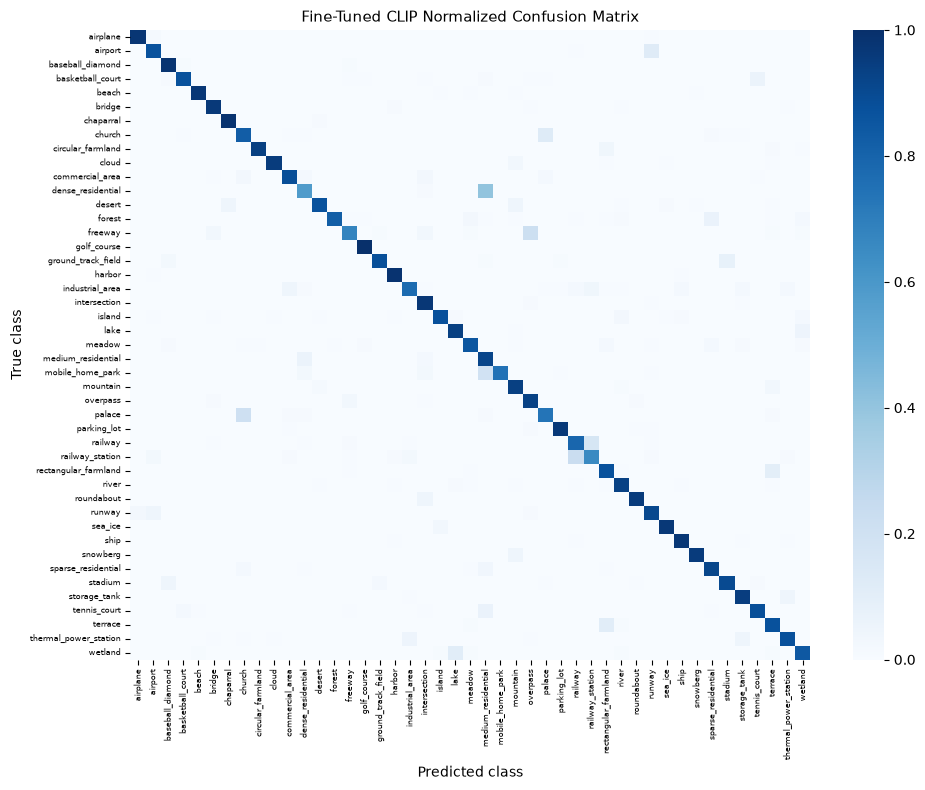

In [58]:
base_labels_np = to_numpy_array(base_full_test_results["labels"]).astype(int)
base_predictions_np = to_numpy_array(base_full_test_results["predictions"]).astype(int)

finetuned_labels_np = to_numpy_array(fine_tuned_full_test_results["labels"]).astype(int)
finetuned_predictions_np = to_numpy_array(fine_tuned_full_test_results["predictions"]).astype(int)

base_cm = confusion_matrix(
    base_labels_np,
    base_predictions_np,
    labels=list(range(num_classes)),
)

ft_cm = confusion_matrix(
    finetuned_labels_np,
    finetuned_predictions_np,
    labels=list(range(num_classes)),
)

ft_cm_normalized = ft_cm.astype(np.float32) / ft_cm.sum(axis=1, keepdims=True)
ft_cm_normalized = np.nan_to_num(ft_cm_normalized)

df_finetuned_top_confusions = get_top_confusions(
    confusion_matrix_array=ft_cm,
    class_names=class_names,
    top_n=10,
)

print("Most frequent fine-tuned confusion pairs:")
display(df_finetuned_top_confusions)

plt.figure(figsize=(10, 8))

sns.heatmap(
    ft_cm_normalized,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False,
    cbar=True,
    vmin=0,
    vmax=1,
)

plt.title("Fine-Tuned CLIP Normalized Confusion Matrix", fontsize=11)
plt.xlabel("Predicted class")
plt.ylabel("True class")

plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

### Question 2 — Effect of LoRA Fine-Tuning

Compare the base CLIP model and the LoRA fine-tuned CLIP model using the overall comparison table, the per-class improvement table, and the confusion matrices. Did fine-tuning improve the model only slightly, or did it substantially change the classification behavior?

### Answer:

The base CLIP model obtained **67.79% Top-1 accuracy** and **94.70% Recall@5**, whereas the LoRA-adapted model obtained **88.70% Top-1** and **99.62% Recall@5** on the same 6,300 test images and canonical prompt. This corresponds to gains of **+20.90 percentage points in Top-1** and **+4.92 points in Recall@5**, so the change is substantial rather than slight.

The per-class changes confirm a major reorganization of the decision boundaries. The largest gains were for `terrace` (**+86.61 points**), `sparse_residential` (**+85.38**), `mountain` (**+80.87**), `medium_residential` (**+78.23**), `airplane` (**+65.09**), and `airport` (**+62.35**). Several confusions were greatly reduced: `airport → runway` fell from 122 to 20 cases and `terrace → rectangular_farmland` from 111 to 14. However, adaptation was not uniformly beneficial: `mobile_home_park` dropped by **21.34 points**, `dense_residential` by **13.19**, and `rectangular_farmland` by **10.37**; the largest remaining confusion was `dense_residential → medium_residential` with 58 cases. Overall, LoRA substantially changed classification behavior while introducing some class-specific regressions. A reproducibility caveat is that the saved training output shows a `KeyboardInterrupt` at 461/2363 batches, so these measurements describe the resulting **partially trained adapter**, not a cleanly completed one-epoch run.


# Part 5 — Text-to-Image Retrieval with CLIP and FAISS

In this part, CLIP embeddings are used for text-to-image retrieval on the RESISC45 test split.

FAISS provides efficient nearest-neighbor search in the embedding space. Since CLIP embeddings are normalized, inner-product search is equivalent to cosine-similarity retrieval.

## 5.1 Section configuration

This cell defines the retrieval query, the Top-k setting, and the batch size used for gallery encoding and search.

In [59]:
PART5_TOP_K = 3
PART5_BATCH_SIZE = FT_EVAL_BATCH_SIZE if "FT_EVAL_BATCH_SIZE" in globals() else BATCH_SIZE

PART5_RETRIEVAL_QUERY = "an overhead view of storage tanks"

# Avoid leaking the old multi-query variable into Part 6.
# Part 6 has its own fallback prompt list.
if "RETRIEVAL_QUERY_EXAMPLES" in globals():
    del RETRIEVAL_QUERY_EXAMPLES

print("Part 5 retrieval configuration")
print("------------------------------")
print("Query:", PART5_RETRIEVAL_QUERY)
print("Top-k:", PART5_TOP_K)
print("Batch size:", PART5_BATCH_SIZE)

Part 5 retrieval configuration
------------------------------
Query: an overhead view of storage tanks
Top-k: 3
Batch size: 16


## 5.2 Select the retrieval model

This cell selects the model used for retrieval.

If the merged fine-tuned CLIP model is available, it is used first. Otherwise, the notebook falls back to the base CLIP model.

In [60]:
def get_retrieval_model():
    if "merged_lora_model" in globals():
        print("Using merged LoRA fine-tuned CLIP model from memory.")
        retrieval_model = merged_lora_model

    elif "MERGED_MODEL_DIR" in globals() and Path(MERGED_MODEL_DIR).exists():
        print("Loading merged LoRA fine-tuned CLIP model from disk.")
        retrieval_model = CLIPModel.from_pretrained(MERGED_MODEL_DIR)

    else:
        print("Fine-tuned model was not found. Falling back to base CLIP.")
        retrieval_model = CLIPModel.from_pretrained(CLIP_MODEL_ID)

    retrieval_model = retrieval_model.to(DEVICE)
    retrieval_model.eval()

    return retrieval_model


retrieval_model = get_retrieval_model()

print("Retrieval model is ready.")
print("Device:", DEVICE)

Using merged LoRA fine-tuned CLIP model from memory.
Retrieval model is ready.
Device: cuda


## 5.3 Build a retrieval dataloader

This cell builds the retrieval gallery from the full RESISC45 test split.

Each image in the gallery becomes one searchable item in the retrieval index.

In [61]:
retrieval_dataset = test_full_dataset

retrieval_loader = DataLoader(
    retrieval_dataset,
    batch_size=PART5_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_pil_batch,
    pin_memory=torch.cuda.is_available(),
)

retrieval_loader_df = pd.DataFrame([
    {
        "gallery": "RESISC45 full test split",
        "num_images": len(retrieval_dataset),
        "batch_size": PART5_BATCH_SIZE,
        "num_batches": len(retrieval_loader),
    }
])

display(retrieval_loader_df)

,gallery,num_images,batch_size,num_batches
0,RESISC45 full test split,6300,16,394


## 5.4 Define embedding helpers for retrieval

This cell defines helper functions for encoding text queries and gallery images.

The embeddings are L2-normalized so that similarity search can be performed with cosine similarity.

In [62]:
@torch.no_grad()
def encode_retrieval_images(model, processor, images, device):
    model.eval()
    inputs = processor(images=images, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)
    features = model.get_image_features(pixel_values=pixel_values)
    return F.normalize(features, dim=-1)


@torch.no_grad()
def encode_retrieval_texts(model, processor, texts, device):
    model.eval()
    inputs = processor(
        text=texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=77,
    )
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }
    features = model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs.get("attention_mask"),
    )
    return F.normalize(features, dim=-1)


## 5.5 Extract image embeddings for the retrieval gallery

This cell encodes all gallery images and stores one CLIP embedding per image.

The result is the feature matrix used to build the retrieval index.

In [63]:
@torch.no_grad()
def build_retrieval_gallery_embeddings(model, processor, dataloader, device):
    model.eval()
    feature_batches = []
    rows = []
    dataset_index = 0

    for batch in tqdm(dataloader, desc="Encoding retrieval gallery"):
        features = encode_retrieval_images(
            model,
            processor,
            batch["images"],
            device,
        )
        feature_batches.append(
            features.detach().cpu().numpy().astype(np.float32)
        )

        for image_id, label, class_name in zip(
            batch["image_ids"],
            batch["labels"].tolist(),
            batch["class_names"],
        ):
            rows.append({
                "gallery_index": dataset_index,
                "dataset_index": dataset_index,
                "image_id": image_id,
                "label": int(label),
                "class_name": class_name,
            })
            dataset_index += 1

    if not feature_batches:
        raise ValueError("The retrieval dataloader is empty.")

    image_features = np.ascontiguousarray(
        np.concatenate(feature_batches, axis=0),
        dtype=np.float32,
    )
    gallery_df = pd.DataFrame(rows)

    if len(image_features) != len(gallery_df):
        raise RuntimeError("Embedding and gallery metadata counts do not match.")

    return image_features, gallery_df


retrieval_image_embeddings, df_retrieval_gallery = build_retrieval_gallery_embeddings(
    model=retrieval_model,
    processor=processor,
    dataloader=retrieval_loader,
    device=DEVICE,
)

embedding_norms = np.linalg.norm(
    retrieval_image_embeddings,
    axis=1,
)

embedding_check_df = pd.DataFrame([
    {
        "num_gallery_images": retrieval_image_embeddings.shape[0],
        "embedding_dim": retrieval_image_embeddings.shape[1],
        "min_norm": embedding_norms.min(),
        "max_norm": embedding_norms.max(),
        "mean_norm": embedding_norms.mean(),
    }
])

display(embedding_check_df)


Encoding retrieval gallery: 100%|██████████| 394/394 [11:24<00:00,  1.74s/it]


,num_gallery_images,embedding_dim,min_norm,max_norm,mean_norm
0,6300,768,1.0,1.0,1.0


## 5.6 Build a FAISS index

This cell builds the FAISS retrieval index.

FAISS is a library for fast similarity search over dense vectors. Here we use `IndexFlatIP`, which performs exact inner-product search. Because the embeddings are normalized, this is equivalent to exact cosine-similarity retrieval.

In [64]:
embedding_dim = retrieval_image_embeddings.shape[1]

retrieval_index = faiss.IndexFlatIP(embedding_dim)
retrieval_index.add(retrieval_image_embeddings)

print("FAISS index created.")
print("Embedding dimension:", embedding_dim)
print("Indexed images:", retrieval_index.ntotal)

FAISS index created.
Embedding dimension: 768
Indexed images: 6300


## 5.7 Text-to-image retrieval function

This function encodes a text query, searches the FAISS index, and returns the top matching images.

The retrieved results are shown as a compact ranked grid.

In [65]:
def retrieve_images_from_text(
    query,
    model,
    processor,
    index,
    gallery_df,
    hf_dataset,
    device,
    top_k=3,
):
    if top_k <= 0:
        raise ValueError("top_k must be positive.")

    query_features = encode_retrieval_texts(
        model,
        processor,
        [query],
        device,
    )
    query_array = np.ascontiguousarray(
        query_features.detach().cpu().numpy(),
        dtype=np.float32,
    )
    effective_k = min(top_k, index.ntotal)
    scores, indices = index.search(query_array, effective_k)

    result_rows = []
    figure, axes = plt.subplots(
        1,
        effective_k,
        figsize=(4 * effective_k, 4),
        squeeze=False,
    )

    for rank, (score, gallery_index) in enumerate(
        zip(scores[0], indices[0]),
        start=1,
    ):
        metadata = gallery_df.iloc[int(gallery_index)]
        dataset_index = int(metadata["dataset_index"])
        image = hf_dataset[dataset_index]["image"].convert("RGB")

        result_rows.append({
            "rank": rank,
            "score": float(score),
            "gallery_index": int(gallery_index),
            "dataset_index": dataset_index,
            "image_id": metadata["image_id"],
            "label": int(metadata["label"]),
            "class_name": metadata["class_name"],
        })

        axis = axes[0, rank - 1]
        axis.imshow(image)
        axis.axis("off")
        axis.set_title(
            f"Rank {rank} | {metadata['class_name']}\n"
            f"cosine={score:.3f}",
            fontsize=9,
        )

    figure.suptitle(f'Text query: "{query}"', fontsize=12)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(result_rows)


## 5.8 Run one retrieval query

This cell runs a single natural-language retrieval query and displays the top retrieved images.

It provides a small qualitative retrieval demo using the CLIP embedding space.

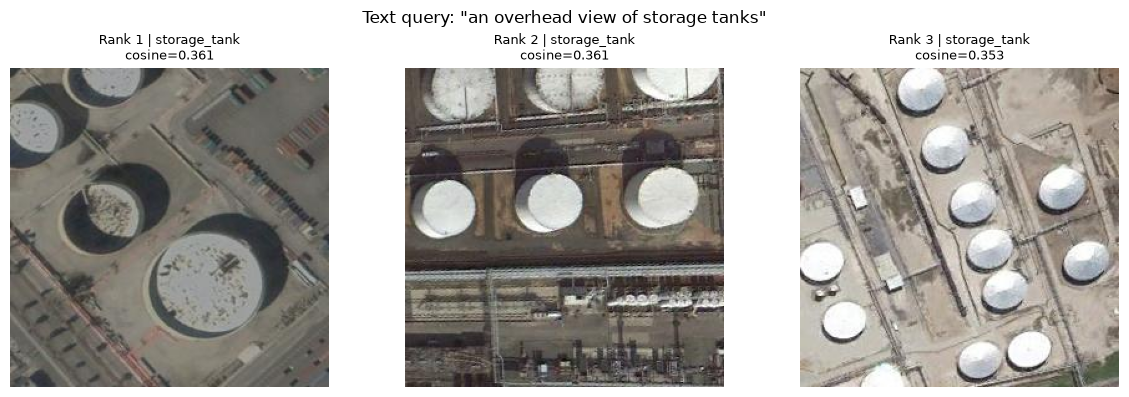

Retrieval query:
an overhead view of storage tanks

Retrieved classes:
storage_tank, storage_tank, storage_tank


In [66]:
df_single_query_results = retrieve_images_from_text(
    query=PART5_RETRIEVAL_QUERY,
    model=retrieval_model,
    processor=processor,
    index=retrieval_index,
    gallery_df=df_retrieval_gallery,
    hf_dataset=test_full_ds,
    device=DEVICE,
    top_k=PART5_TOP_K,
)

print("Retrieval query:")
print(PART5_RETRIEVAL_QUERY)

print("\nRetrieved classes:")
print(", ".join(df_single_query_results["class_name"].tolist()))

# Part 6 — Stable Diffusion with the Fine-Tuned CLIP Text Encoder

In this part, we test how the fine-tuned CLIP text encoder affects image generation in Stable Diffusion.

Stable Diffusion is a latent diffusion model: the text encoder maps a prompt to conditioning embeddings, the U-Net denoises latent noise conditioned on these embeddings, and the VAE decodes the final latent into an image.

Here, we replace only the text encoder and compare generation before and after the replacement.

## 6.1 Part 6 configuration

This cell defines the main generation settings for Stable Diffusion, including image size, inference steps, guidance scale, negative prompt, and the test prompts used for comparison.

In [ ]:
SD_GENERATION_HEIGHT = 512
SD_GENERATION_WIDTH = 512
SD_NUM_INFERENCE_STEPS = 5
#########10
SD_GUIDANCE_SCALE = 7.5
SD_NEGATIVE_PROMPT = "low quality, blurry, distorted, noisy, artifacts"

SD_TEST_PROMPTS = [
    "a satellite image of an airport with runways",
    "an aerial image of a harbor with ships and water",
    "an overhead view of large circular storage tanks",
]

SD_BASE_SEED = 123

SD_DISPLAY_FIGURE_WIDTH = 8
SD_DISPLAY_ROW_HEIGHT = 2.8

print("Part 6 configuration")
print("--------------------")
print("Stable Diffusion model:", SD_MODEL_ID)
print("CLIP model:", CLIP_MODEL_ID)
print("Number of prompts:", len(SD_TEST_PROMPTS))
print("Generation image size:", SD_GENERATION_HEIGHT, "x", SD_GENERATION_WIDTH)
print("Inference steps:", SD_NUM_INFERENCE_STEPS)
print("Guidance scale:", SD_GUIDANCE_SCALE)

print("\nPrompts:")
for prompt in SD_TEST_PROMPTS:
    print("-", prompt)

Part 6 configuration
--------------------
Stable Diffusion model: runwayml/stable-diffusion-v1-5
CLIP model: openai/clip-vit-large-patch14
Number of prompts: 3
Generation image size: 512 x 512
Inference steps: 5
Guidance scale: 7.5

Prompts:
- a satellite image of an airport with runways
- an aerial image of a harbor with ships and water
- an overhead view of large circular storage tanks


## 6.2 Free GPU and CPU memory

In [68]:
objects_to_delete = [
    # Part 0-3 models and helpers
    "model",
    "zero_shot_classifier",
    "prompt_evaluator",

    # Part 4 training objects
    "lora_model",
    "fine_tuner",
    "base_eval_model",

    # Part 5 retrieval objects
    "retrieval_model",
    "retrieval_index",
    "retrieval_image_embeddings",
    "df_retrieval_gallery",
    "df_single_query_results",
    "all_query_results",

    # Previous Part 6 objects, if this section is re-run
    "sd_pipe",
    "base_sd_images",
    "finetuned_sd_images",
    "original_sd_text_encoder",
    "fine_tuned_sd_text_encoder",
    "sd_compatible_text_encoder",
    "fine_tuned_clip_for_sd",
    "fine_tuned_text_source",
    "fine_tuned_clip_source",
    "source_text_state_dict",
    "text_encoder_copy_report",
]

for object_name in objects_to_delete:
    if object_name in globals():
        try:
            del globals()[object_name]
            print(f"Deleted {object_name}.")
        except Exception as error:
            print(f"Could not delete {object_name}:", repr(error))

if "merged_lora_model" in globals():
    if "MERGED_MODEL_DIR" in globals() and Path(MERGED_MODEL_DIR).exists():
        del merged_lora_model
        print("Deleted merged_lora_model because MERGED_MODEL_DIR exists.")
    else:
        merged_lora_model = merged_lora_model.to("cpu")
        print("Kept merged_lora_model on CPU because MERGED_MODEL_DIR was not found.")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

try:
    import psutil

    process = psutil.Process(os.getpid())
    ram_used_gb = process.memory_info().rss / 1e9
    print(f"Current Python process RAM usage: {ram_used_gb:.2f} GB")
except Exception as error:
    print("Could not report RAM usage:", repr(error))

print("Memory cleanup complete.")

Deleted model.
Deleted zero_shot_classifier.
Deleted prompt_evaluator.
Deleted retrieval_model.
Deleted retrieval_index.
Deleted retrieval_image_embeddings.
Deleted df_retrieval_gallery.
Deleted df_single_query_results.
Deleted merged_lora_model because MERGED_MODEL_DIR exists.
Current Python process RAM usage: 1.28 GB
Memory cleanup complete.


## 6.3 Load Stable Diffusion v1.5

This cell loads the baseline Stable Diffusion v1.5 pipeline.

The scheduler and memory-saving options are configured so the pipeline can run more efficiently in the notebook environment.

In [ ]:
SD_PIPELINE_MODEL_ID = SD_MODEL_ID
SD_DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32

sd_pipe = StableDiffusionPipeline.from_pretrained(
    SD_PIPELINE_MODEL_ID,
    torch_dtype=SD_DTYPE,
    safety_checker=None,
    requires_safety_checker=False,
)

sd_pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    sd_pipe.scheduler.config
)

if torch.cuda.is_available():
    sd_pipe = sd_pipe.to(DEVICE)
else:
    sd_pipe = sd_pipe.to("cpu")

sd_pipe.enable_attention_slicing()

try:
    sd_pipe.enable_vae_slicing()
except Exception as error:
    print("Could not enable VAE slicing:", repr(error))

print("Stable Diffusion pipeline loaded.")
print("Pipeline device:", DEVICE)
print("Pipeline dtype:", SD_DTYPE)
print("Original SD text encoder:", type(sd_pipe.text_encoder))

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Fetching 14 files:  93%|█████████▎| 13/14 [00:11<00:00,  1.11it/s]Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] d

ChunkedEncodingError: ('Connection broken: IncompleteRead(118847463 bytes read, 1054395917 more expected)', IncompleteRead(118847463 bytes read, 1054395917 more expected))

## 6.4 Load the fine-tuned CLIP text encoder and make it Stable-Diffusion-compatible

Stable Diffusion uses a `CLIPTextModel` to encode prompts.

This cell loads the fine-tuned text-encoder weights from Part 4, builds a text encoder with the same configuration as Stable Diffusion, and copies all compatible weights into it.

Only the text-conditioning module is replaced; the U-Net and VAE remain unchanged.

In [80]:
from pathlib import Path

SD_WEIGHT_FILE = Path("./diffusion_pytorch_model.safetensors").resolve()

print("Current folder:", Path.cwd())
print("Weight file:", SD_WEIGHT_FILE)
print("Exists:", SD_WEIGHT_FILE.exists())
print("Size:", round(SD_WEIGHT_FILE.stat().st_size / 1024**3, 2), "GB")
from pathlib import Path
from diffusers import UNet2DConditionModel
from safetensors.torch import load_file

SD_WEIGHT_FILE = Path(
    "./diffusion_pytorch_model.safetensors"
).resolve()

assert SD_WEIGHT_FILE.exists(), f"File not found: {SD_WEIGHT_FILE}"

print("Weight file:", SD_WEIGHT_FILE)
print("Size:", round(SD_WEIGHT_FILE.stat().st_size / 1024**3, 2), "GB")

# نکتهٔ اصلی: subfolder="unet"
unet_config = UNet2DConditionModel.load_config(
    "runwayml/stable-diffusion-v1-5",
    subfolder="unet",
    cache_dir=str(CACHE_DIR),
)

unet = UNet2DConditionModel.from_config(unet_config)

state_dict = load_file(
    str(SD_WEIGHT_FILE),
    device="cpu",
)

load_result = unet.load_state_dict(
    state_dict,
    strict=True,
)

del state_dict

print("UNet weights loaded successfully")
print(load_result)

Current folder: i:\دانشگاه\ترم 8\Deep learning\HW\HW5
Weight file: I:\دانشگاه\ترم 8\Deep learning\HW\HW5\diffusion_pytorch_model.safetensors
Exists: True
Size: 3.2 GB
Weight file: I:\دانشگاه\ترم 8\Deep learning\HW\HW5\diffusion_pytorch_model.safetensors
Size: 3.2 GB


c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:147: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in I:\content\resisc45_clip_project\hf_cache\models--runwayml--stable-diffusion-v1-5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


UNet weights loaded successfully
<All keys matched successfully>


In [81]:
from diffusers import StableDiffusionPipeline

sd_pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    cache_dir=str(CACHE_DIR),
    unet=unet,  # استفاده از فایل ۳.۲ گیگابایتی محلی
    torch_dtype=SD_DTYPE,
    safety_checker=None,
    requires_safety_checker=False,
)

sd_pipe = sd_pipe.to(DEVICE)

print("Stable Diffusion loaded successfully")

Fetching 13 files:  85%|████████▍ | 11/13 [00:13<00:02,  1.24s/it]Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Error while downloading from [temporary signed download URL removed] [SSL: DECRYPTION_FAILED_OR_BAD_RECORD_MAC] decryption failed or bad record mac (_ssl.c:2559)
Trying to resume download...
Loading pipeline components...:  50%|█████     | 3/6 [00:01<00:02,  1.48it/s]c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then

Stable Diffusion loaded successfully


In [82]:

sd_pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    sd_pipe.scheduler.config
)

if torch.cuda.is_available():
    sd_pipe = sd_pipe.to(DEVICE)
else:
    sd_pipe = sd_pipe.to("cpu")

sd_pipe.enable_attention_slicing()

try:
    sd_pipe.enable_vae_slicing()
except Exception as error:
    print("Could not enable VAE slicing:", repr(error))

print("Stable Diffusion pipeline loaded.")
print("Pipeline device:", DEVICE)
print("Pipeline dtype:", SD_DTYPE)
print("Original SD text encoder:", type(sd_pipe.text_encoder))

Stable Diffusion pipeline loaded.
Pipeline device: cuda
Pipeline dtype: torch.float16
Original SD text encoder: <class 'transformers.models.clip.modeling_clip.CLIPTextModel'>


In [83]:
def cleanup_failed_part6_objects():
    for object_name in [
        "fine_tuned_text_source",
        "fine_tuned_clip_source",
        "fine_tuned_sd_text_encoder",
        "source_text_state_dict",
    ]:
        if object_name in globals():
            try:
                del globals()[object_name]
                print(f"Deleted old {object_name}.")
            except Exception as error:
                print(f"Could not delete {object_name}:", repr(error))

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


cleanup_failed_part6_objects()


def load_finetuned_text_encoder_state_dict():
    if "merged_lora_model" in globals():
        source_model = merged_lora_model
        source_description = "merged_lora_model in memory"
        owns_source_model = False
    elif "MERGED_MODEL_DIR" in globals() and Path(MERGED_MODEL_DIR).exists():
        source_model = CLIPModel.from_pretrained(
            MERGED_MODEL_DIR,
            low_cpu_mem_usage=True,
        )
        source_description = str(MERGED_MODEL_DIR)
        owns_source_model = True
    else:
        raise FileNotFoundError(
            "The merged fine-tuned CLIP model was not found. "
            "Run Part 4.11 before Part 6."
        )

    state_dict = {
        key: value.detach().cpu().clone()
        for key, value in source_model.text_model.state_dict().items()
    }

    if owns_source_model:
        del source_model
        gc.collect()

    print("Loaded fine-tuned text weights from:", source_description)
    print("Source text tensors:", len(state_dict))
    return state_dict


def copy_matching_text_weights(source_state_dict, target_text_encoder):
    target_state_dict = target_text_encoder.state_dict()

    copied_keys = []
    skipped_keys = []

    for source_key, source_value in source_state_dict.items():
        candidate_keys = [source_key]

        if source_key.startswith("text_model."):
            candidate_keys.append(source_key.replace("text_model.", "", 1))
        else:
            candidate_keys.append("text_model." + source_key)

        matched = False

        for target_key in candidate_keys:
            if target_key in target_state_dict:
                if target_state_dict[target_key].shape == source_value.shape:
                    target_state_dict[target_key] = source_value.to(
                        dtype=target_state_dict[target_key].dtype
                    )
                    copied_keys.append((source_key, target_key))
                    matched = True
                    break

        if not matched:
            skipped_keys.append(source_key)

    load_result = target_text_encoder.load_state_dict(
        target_state_dict,
        strict=True,
    )

    return {
        "load_result": load_result,
        "copied_keys": copied_keys,
        "skipped_keys": skipped_keys,
        "num_target_keys": len(target_state_dict),
    }


def build_sd_compatible_text_encoder_from_finetuned_weights(sd_pipe):
    source_state_dict = load_finetuned_text_encoder_state_dict()
    target_text_encoder = CLIPTextModel(sd_pipe.text_encoder.config)

    copy_report = copy_matching_text_weights(
        source_state_dict,
        target_text_encoder,
    )

    copied_target_keys = {
        target_key
        for _, target_key in copy_report["copied_keys"]
    }
    missing_target_count = (
        copy_report["num_target_keys"] - len(copied_target_keys)
    )

    print("Copied tensors:", len(copy_report["copied_keys"]))
    print("Skipped source tensors:", len(copy_report["skipped_keys"]))
    print("Unmatched target tensors:", missing_target_count)

    if missing_target_count > 0:
        raise RuntimeError(
            "The fine-tuned and Stable Diffusion text encoders are not fully "
            "architecture-compatible; refusing to use partially random weights."
        )

    target_text_encoder.eval()
    for parameter in target_text_encoder.parameters():
        parameter.requires_grad_(False)

    del source_state_dict
    gc.collect()
    return target_text_encoder, copy_report


fine_tuned_sd_text_encoder, text_encoder_copy_report = (
    build_sd_compatible_text_encoder_from_finetuned_weights(sd_pipe)
)

print("Fine-tuned SD-compatible text encoder is ready.")
print(type(fine_tuned_sd_text_encoder))


Loaded fine-tuned text weights from: \content\resisc45_clip_project\outputs\part4_lora_finetuning\clip_resisc45_lora_merged
Source text tensors: 196
Copied tensors: 196
Skipped source tensors: 0
Unmatched target tensors: 0
Fine-tuned SD-compatible text encoder is ready.
<class 'transformers.models.clip.modeling_clip.CLIPTextModel'>


## 6.5 Generation helper functions

This cell defines helper functions for image generation and visualization.

The same random seeds are used before and after replacing the text encoder so the comparison is more controlled.

In [84]:
def get_generator(seed):
    generator_device = "cuda" if torch.cuda.is_available() else "cpu"
    generator = torch.Generator(device=generator_device)
    generator.manual_seed(int(seed))
    return generator


@torch.no_grad()
def generate_images_with_sd_pipeline(
    pipe,
    prompts,
    negative_prompt=None,
    num_inference_steps=30,
    guidance_scale=7.5,
    height=512,
    width=512,
    base_seed=123,
):
    generated_images = []

    for prompt_index, prompt in enumerate(
        tqdm(prompts, desc="Stable Diffusion generation")
    ):
        generator = get_generator(base_seed + prompt_index)
        output = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            height=height,
            width=width,
            generator=generator,
        )
        generated_images.append(output.images[0])

    return generated_images


def show_side_by_side_generation_comparison(
    prompts,
    base_images,
    finetuned_images,
    figure_width=8,
    row_height=2.8,
):
    if not (
        len(prompts) == len(base_images) == len(finetuned_images)
    ):
        raise ValueError(
            "prompts, base_images, and finetuned_images must have equal lengths."
        )

    figure, axes = plt.subplots(
        len(prompts),
        2,
        figsize=(figure_width, row_height * len(prompts)),
        squeeze=False,
    )

    for row_index, prompt in enumerate(prompts):
        axes[row_index, 0].imshow(base_images[row_index])
        axes[row_index, 0].axis("off")
        axes[row_index, 0].set_title(
            f"Base text encoder\n{prompt}",
            fontsize=9,
        )

        axes[row_index, 1].imshow(finetuned_images[row_index])
        axes[row_index, 1].axis("off")
        axes[row_index, 1].set_title(
            f"Fine-tuned text encoder\n{prompt}",
            fontsize=9,
        )

    figure.suptitle(
        "Stable Diffusion: Original vs Fine-Tuned CLIP Text Encoder",
        fontsize=12,
    )
    plt.tight_layout()
    plt.show()


## 6.6 Generate baseline images with the original Stable Diffusion text encoder

This cell first generates baseline images with the original Stable Diffusion text encoder.

Then it replaces the text encoder with the fine-tuned CLIP version, generates images again with the same prompts and seeds, and displays both outputs side by side for comparison.

In [93]:
import torch

if str(DEVICE).startswith("cuda"):
    INFERENCE_DTYPE = torch.float16
else:
    INFERENCE_DTYPE = torch.float32

sd_pipe = sd_pipe.to(
    device=DEVICE,
    dtype=INFERENCE_DTYPE,
)

print("UNet dtype:", next(sd_pipe.unet.parameters()).dtype)
print("Text encoder dtype:", next(sd_pipe.text_encoder.parameters()).dtype)
print("VAE dtype:", next(sd_pipe.vae.parameters()).dtype)

UNet dtype: torch.float16
Text encoder dtype: torch.float16
VAE dtype: torch.float16


In [92]:
import torch

sd_pipe.unet.to(device=DEVICE, dtype=torch.float16)
sd_pipe.text_encoder.to(device=DEVICE, dtype=torch.float16)

# رمزگشایی تصویر در float32 برای جلوگیری از NaN و تصویر سیاه
sd_pipe.vae.to(device=DEVICE, dtype=torch.float32)

sd_pipe.unet.eval()
sd_pipe.text_encoder.eval()
sd_pipe.vae.eval()

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

In [95]:
result = sd_pipe(
    prompt=SD_TEST_PROMPTS[0],
    num_inference_steps=20,
    height=512,
    width=512,
    output_type="np",
)

image = result.images[0]

print("Min:", image.min())
print("Max:", image.max())
print("Mean:", image.mean())
print("Has NaN:", np.isnan(image).any())

100%|██████████| 20/20 [01:18<00:00,  3.94s/it]


Min: nan
Max: nan
Mean: nan
Has NaN: True


Generating baseline Stable Diffusion images...


Stable Diffusion generation: 100%|██████████| 3/3 [02:12<00:00, 44.08s/it]


Replacing Stable Diffusion text encoder with the fine-tuned CLIP text encoder...
Generating images with the fine-tuned text encoder...


Stable Diffusion generation: 100%|██████████| 3/3 [01:55<00:00, 38.64s/it]


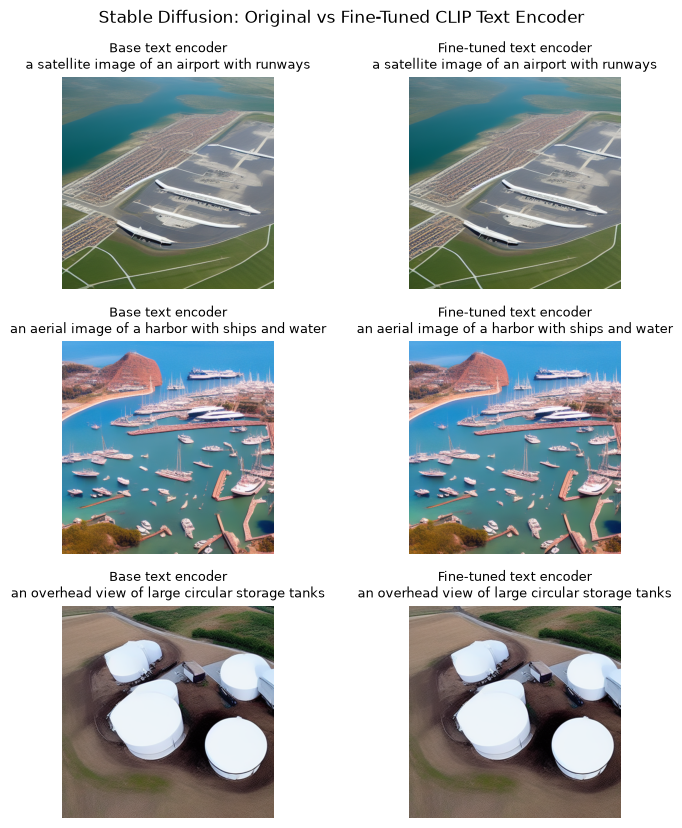

Comparison complete.
Original text encoder: <class 'transformers.models.clip.modeling_clip.CLIPTextModel'>
Fine-tuned text encoder: <class 'transformers.models.clip.modeling_clip.CLIPTextModel'>


In [99]:
original_sd_text_encoder = sd_pipe.text_encoder

print("Generating baseline Stable Diffusion images...")

base_sd_images = generate_images_with_sd_pipeline(
    pipe=sd_pipe,
    prompts=SD_TEST_PROMPTS,
    negative_prompt=SD_NEGATIVE_PROMPT,
    num_inference_steps=SD_NUM_INFERENCE_STEPS,
    guidance_scale=SD_GUIDANCE_SCALE,
    height=SD_GENERATION_HEIGHT,
    width=SD_GENERATION_WIDTH,
    base_seed=SD_BASE_SEED,
)

print("Replacing Stable Diffusion text encoder with the fine-tuned CLIP text encoder...")

sd_pipe.text_encoder = fine_tuned_sd_text_encoder.to(
    device=DEVICE,
    dtype=SD_DTYPE,
)

sd_pipe.text_encoder.eval()

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Generating images with the fine-tuned text encoder...")

finetuned_sd_images = generate_images_with_sd_pipeline(
    pipe=sd_pipe,
    prompts=SD_TEST_PROMPTS,
    negative_prompt=SD_NEGATIVE_PROMPT,
    num_inference_steps=SD_NUM_INFERENCE_STEPS,
    guidance_scale=SD_GUIDANCE_SCALE,
    height=SD_GENERATION_HEIGHT,
    width=SD_GENERATION_WIDTH,
    base_seed=SD_BASE_SEED,
)

show_side_by_side_generation_comparison(
    prompts=SD_TEST_PROMPTS,
    base_images=base_sd_images,
    finetuned_images=finetuned_sd_images,
    figure_width=SD_DISPLAY_FIGURE_WIDTH,
    row_height=SD_DISPLAY_ROW_HEIGHT,
)

print("Comparison complete.")
print("Original text encoder:", type(original_sd_text_encoder))
print("Fine-tuned text encoder:", type(sd_pipe.text_encoder))

In [96]:
import torch

SD_DTYPE = torch.float32

if "original_sd_text_encoder" in globals():
    sd_pipe.text_encoder = original_sd_text_encoder

sd_pipe.unet.to(device=DEVICE, dtype=torch.float32)
sd_pipe.text_encoder.to(device=DEVICE, dtype=torch.float32)
sd_pipe.vae.to(device=DEVICE, dtype=torch.float32)

sd_pipe.unet.eval()
sd_pipe.text_encoder.eval()
sd_pipe.vae.eval()

print("UNet:", next(sd_pipe.unet.parameters()).dtype)
print("Text encoder:", next(sd_pipe.text_encoder.parameters()).dtype)
print("VAE:", next(sd_pipe.vae.parameters()).dtype)

UNet: torch.float32
Text encoder: torch.float32
VAE: torch.float32


In [97]:
result = sd_pipe(
    prompt=SD_TEST_PROMPTS[0],
    negative_prompt=SD_NEGATIVE_PROMPT,
    num_inference_steps=10,
    guidance_scale=SD_GUIDANCE_SCALE,
    height=256,
    width=256,
    output_type="np",
)

100%|██████████| 10/10 [00:10<00:00,  1.05s/it]


In [98]:
import numpy as np

image = result.images[0]

print("All finite:", np.isfinite(image).all())
print("Has NaN:", np.isnan(image).any())
print("Min:", np.nanmin(image))
print("Max:", np.nanmax(image))
print("Mean:", np.nanmean(image))

All finite: True
Has NaN: False
Min: 0.0
Max: 1.0
Mean: 0.6065681


### Question 3 — Retrieval and Generation After Fine-Tuning

The fine-tuned CLIP model is used for text-to-image retrieval, and its text encoder is also inserted into Stable Diffusion. Compare the retrieval result for the storage-tank query with the side-by-side Stable Diffusion generations. Does the fine-tuned representation transfer well to both retrieval and generation?

### Answer:

For retrieval, transfer is clearly successful. For the query **“an overhead view of storage tanks,”** all three retrieved images are visually relevant and all three have the ground-truth label `storage_tank`. Their cosine similarities are approximately **0.361, 0.361, and 0.353**, showing that the fine-tuned CLIP space aligns this in-domain text query with the correct aerial images.

The generation result is different: with identical prompts and seeds, the baseline and fine-tuned-text-encoder images are almost indistinguishable for the airport, harbor, and storage-tank prompts. There is no consistent visible improvement in prompt fidelity or remote-sensing style. Thus, the current outputs support **strong discriminative transfer to retrieval but no clear generative improvement**. This is plausible because Stable Diffusion's U-Net was trained with the distribution of its original text encoder, while LoRA optimized the encoder for CLIP contrastive classification/retrieval rather than diffusion conditioning. The generation conclusion is also preliminary because the displayed comparison used only five denoising steps, and after the later float32/NaN fix the full side-by-side comparison was not regenerated.
